# 预处理与候选检测

按功能合并的报告：先给主要结果，附录保留早期实验与复核记录。各章节的数据范围、阈值版本和输出彼此独立。

运行某一章节时，先重启 kernel，再从该章节的初始化单元开始；人工交互章节按其中的说明操作。运行对应的 builder 会更新该章节，其他章节保持不变。

## 两家机构的连续 EEG 滤波示例

每家机构按文件名字典序取第一份 Train EDF；展示 30–40 秒的全部 16 通道，左右波形使用相同尺度。功率谱取启动保护期后整段信号，先逐通道 Welch，再在线性功率上平均。EDF 已保存信号可能含采集端滤波；本图仅示意额外的 60 Hz notch → 0.5–30 Hz 因果滤波，不用于推断机构差异。

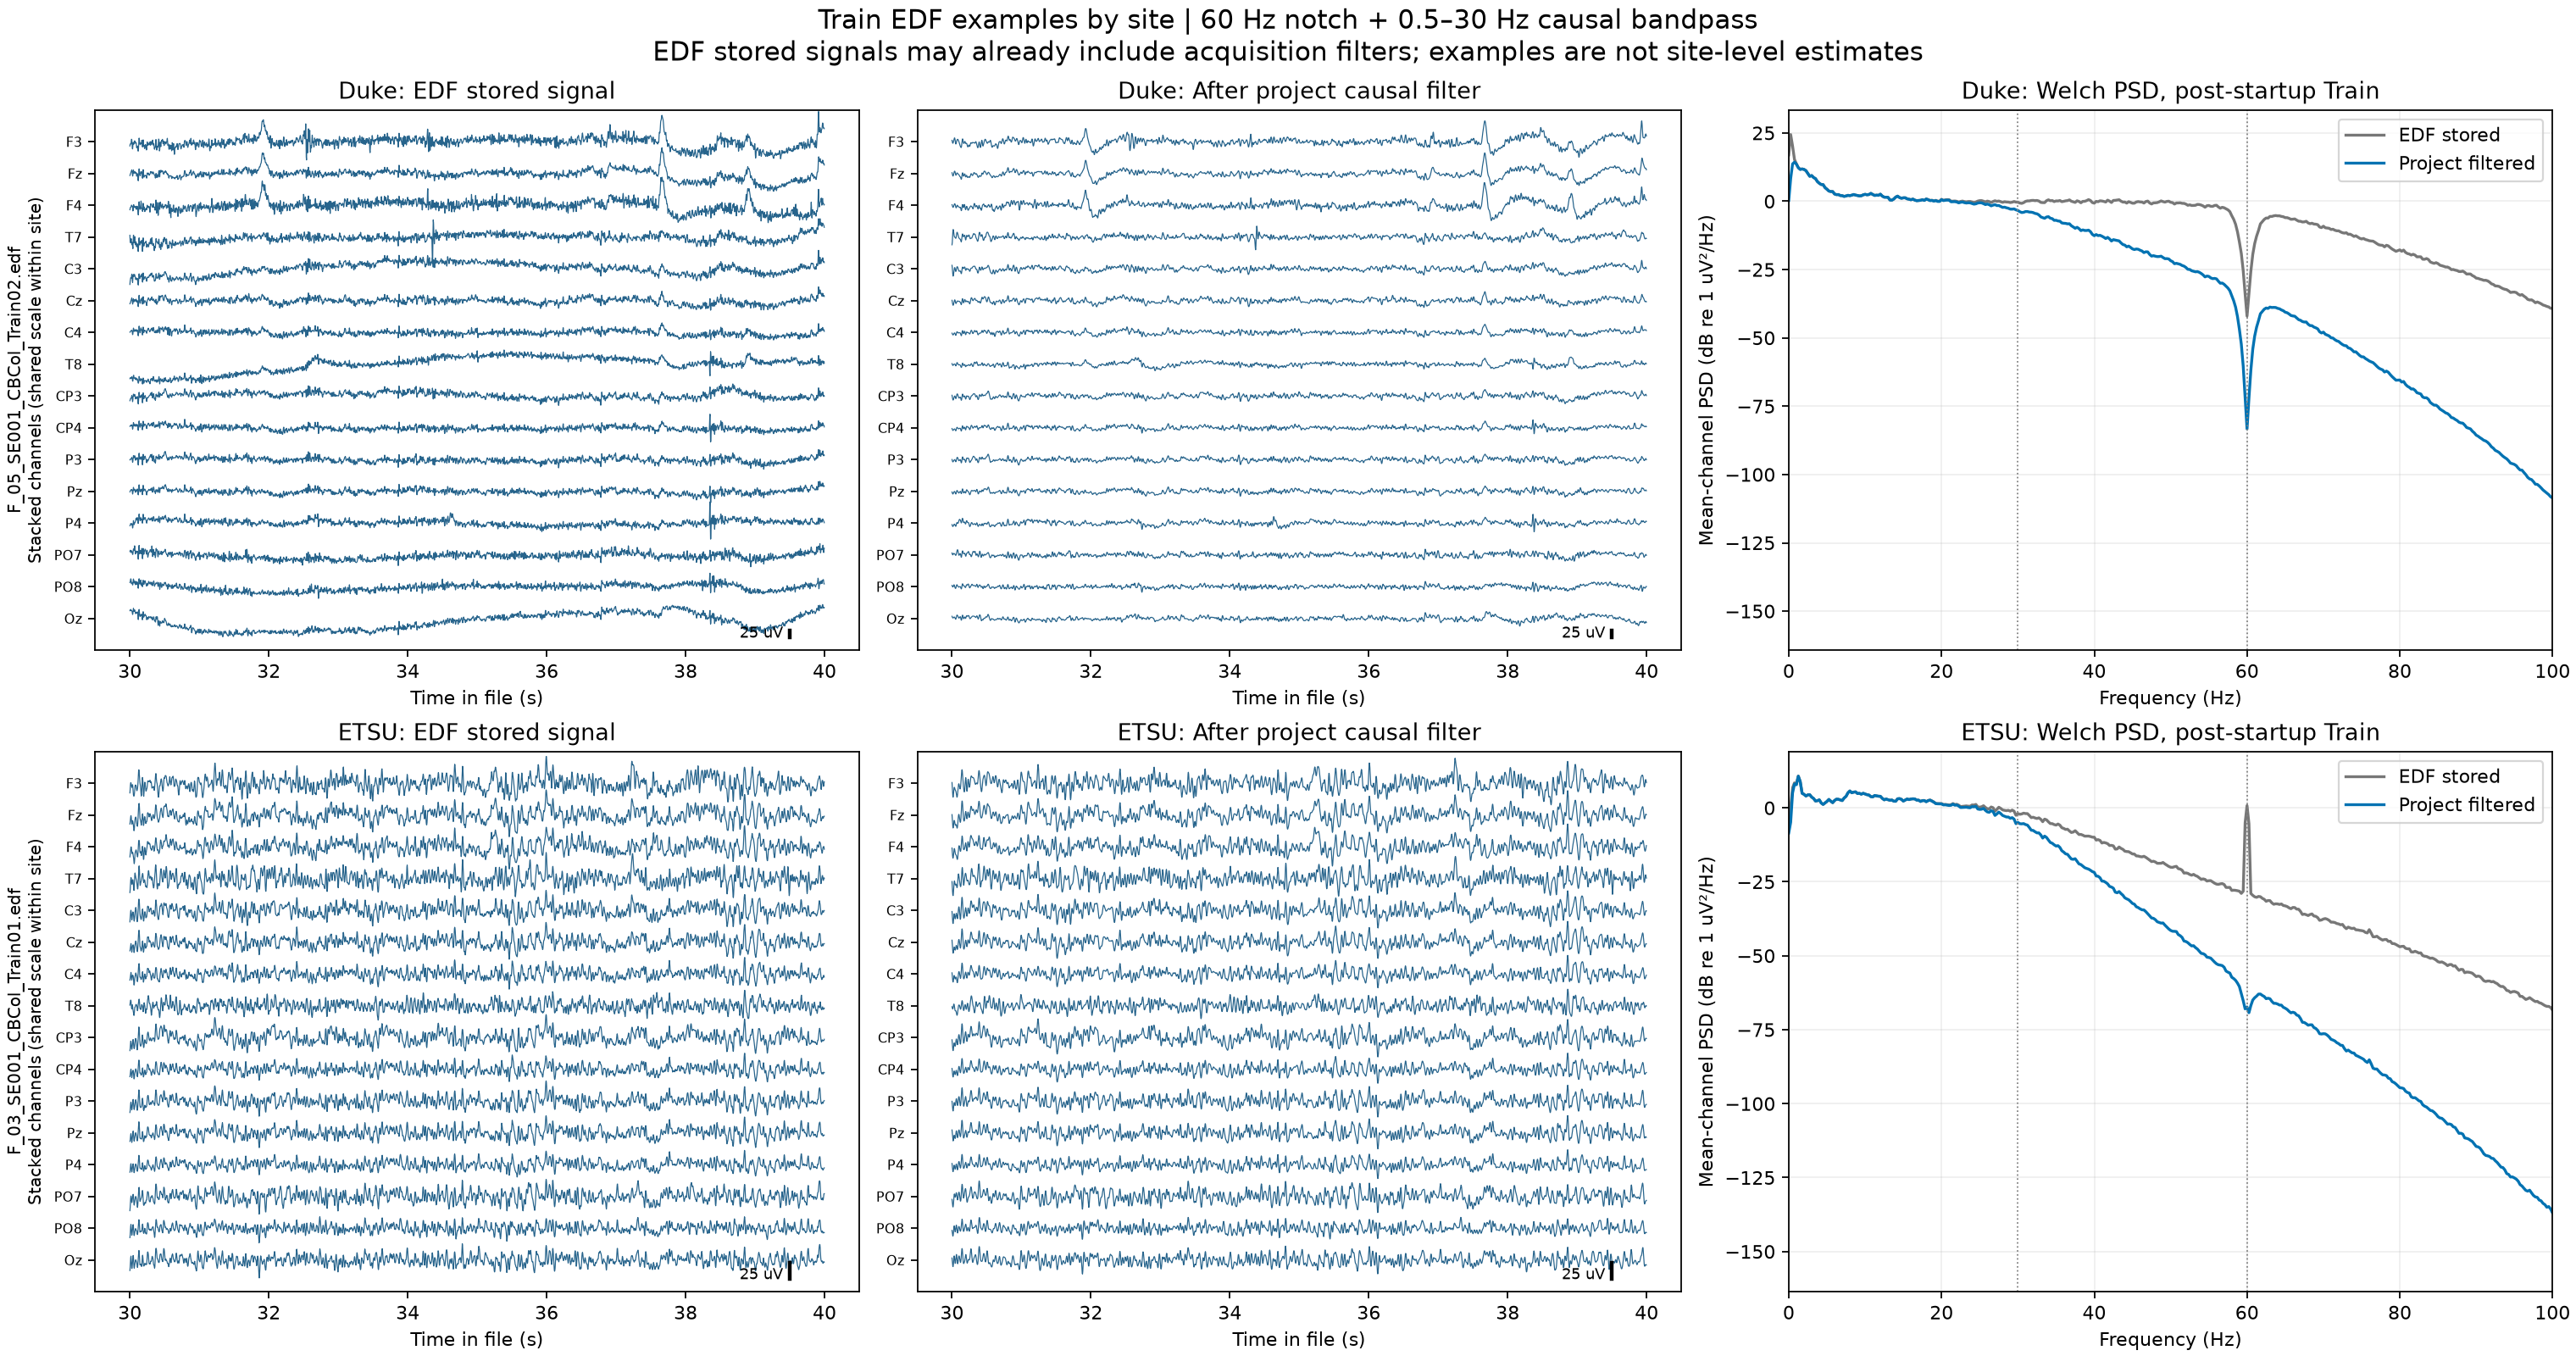

In [1]:
from pathlib import Path
from IPython.display import display, Image
_filter_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs').is_dir())
display(Image(filename=str(_filter_root / 'outputs/filter_site_examples/filter_by_site.png')))


---

## 主要结果：bigp3bci_expanded_candidate_pilot

# 扩展训练 pilot：事件审计、独立眨眼候选与 PTP 模拟

本轮实际运行生成产物的代码，不只是改图注。正式分析信号仍为 **60 Hz notch → 0.5–30 Hz 因果 SOS**；只有EEG被处理，原始EDF与状态未改，事件不移动，连续文件保留状态，不跨文件传状态。0–800 ms半开样本窗口与baseline=None沿用05。

新增分支输出候选和统计，**不新增自动删除、插值或重参考，不训练模型**。本notebook读取保存产物；前一版05已追加本轮概览。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/expanded_pilot.json').exists())
OUT=ROOT/'outputs/expanded_pilot'
manifest=pd.read_csv(OUT/'selection_manifest.csv')
audit=pd.read_csv(OUT/'event_audit.csv')
events=pd.read_csv(OUT/'all_events.csv')
blinks=pd.read_csv(OUT/'all_blinks.csv')
quality=pd.read_csv(OUT/'all_quality.csv')
parameters=json.loads((OUT/'config_snapshot.json').read_text())
EXAMPLE_EDF='F_05_SE001_CBCol_Train02.edf' # 可改为manifest中任意文件
EDF_DIR=OUT/Path(EXAMPLE_EDF).stem
def picture(name,width=1200):display(Image(filename=str(OUT/'figures'/name),width=width))
print(json.dumps(json.loads((OUT/'run_summary.json').read_text()),indent=2))

{
  "n_files": 8,
  "subjects": [
    "F_03",
    "F_05",
    "F_06",
    "F_20"
  ],
  "sessions_per_subject": {
    "F_03": 2,
    "F_05": 2,
    "F_06": 2,
    "F_20": 2
  },
  "n_events": 6030,
  "n_blink_candidates": 226,
  "n_basic_candidates": 159,
  "event_counts": {
    "F_03_SE001_CBCol_Train01.edf": 756,
    "F_03_SE002_CBCol_Train01.edf": 756,
    "F_05_SE001_CBCol_Train02.edf": 756,
    "F_05_SE002_CBCol_Train01.edf": 756,
    "F_06_SE001_CBCol_Train01.edf": 756,
    "F_06_SE002_CBCol_Train01.edf": 756,
    "F_20_SE001_CBCol_Train01.edf": 756,
    "F_20_SE002_CBCol_Train01.edf": 738
  },
  "thresholds_validated": false,
  "automatic_epoch_rejection": false
}


## 1. 固定的文件选择，避免按检测结果挑选

四名被试F_03/F_05/F_06/F_20；每人取最早两个可用Session；每Session取字典序第一份Train/CBCol EDF。manifest在读取信号、检测候选前写入；后续重复运行若选择变化会报错。两站映射仍为inferred。没有使用任何Test EDF。

In [2]:
display(manifest.reset_index(names='zero_based_index'))
print('下面图中file index为上表zero_based_index + 1。')

,zero_based_index,subject_id,session_id,site,site_status,edf_name,relative_path,selection_reason
0,0,F_03,SE001,ETSU,inferred,F_03_SE001_CBCol_Train01.edf,F_03\SE001\Train\CBCol\F_03_SE001_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
1,1,F_03,SE002,ETSU,inferred,F_03_SE002_CBCol_Train01.edf,F_03\SE002\Train\CBCol\F_03_SE002_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
2,2,F_05,SE001,Duke,inferred,F_05_SE001_CBCol_Train02.edf,F_05\SE001\Train\CBCol\F_05_SE001_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
3,3,F_05,SE002,Duke,inferred,F_05_SE002_CBCol_Train01.edf,F_05\SE002\Train\CBCol\F_05_SE002_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
4,4,F_06,SE001,Duke,inferred,F_06_SE001_CBCol_Train01.edf,F_06\SE001\Train\CBCol\F_06_SE001_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
5,5,F_06,SE002,Duke,inferred,F_06_SE002_CBCol_Train01.edf,F_06\SE002\Train\CBCol\F_06_SE002_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
6,6,F_20,SE001,ETSU,inferred,F_20_SE001_CBCol_Train01.edf,F_20\SE001\Train\CBCol\F_20_SE001_CBCol_Train0...,subjects fixed before detection; earliest 2 av...
7,7,F_20,SE002,ETSU,inferred,F_20_SE002_CBCol_Train01.edf,F_20\SE002\Train\CBCol\F_20_SE002_CBCol_Train0...,subjects fixed before detection; earliest 2 av...


下面图中file index为上表zero_based_index + 1。


## 2. 直接核对原始状态值、flash onset与标签读取

独立读取EDF int16数字样本和header缩放，与MNE读取的状态逐项核查。`StimulusType`原始0/1和浏览器事件码1/2是不同概念。保留原有0→non-target、1→target语义，并输出exact-value一致性；不靠四舍五入掩盖非预期值。

flash取`StimulusBegin`由≤0.5跃迁到>0.5的样本，在**同一个onset样本**读取StimulusType；另存前一个/后一个样本值用于核对是否存在错位。独立边沿提取与现有helper一致性逐文件检查，若不同则停止，不按预期改计数。

In [3]:
display(audit[['edf_name','stimulus_type_unique','stimulus_type_unique_at_flash','flash_count','helper_onsets_match',
               'helper_exact_label_mismatch','mne_matches_edf_physical_stimulus_type','sample_zero_active']])
counts=[]
for _,r in manifest.iterrows():
    c=pd.read_csv(OUT/Path(r.edf_name).stem/'state_value_counts.csv')
    counts.append(c[c.channel.eq('StimulusType') & c.representation.eq('raw_edf_digital')].assign(edf_name=r.edf_name))
display(pd.concat(counts,ignore_index=True))
state_examples=pd.read_csv(EDF_DIR/'events_audited.csv')
display(state_examples[['onset_sample','stimulus_begin_previous','stimulus_begin_at_onset','stimulus_type_previous',
                        'stimulus_type_raw','stimulus_type_next','stimulus_type_digital','stimulus_type_physical','event_code','label']].head(12))

,edf_name,stimulus_type_unique,stimulus_type_unique_at_flash,flash_count,helper_onsets_match,helper_exact_label_mismatch,mne_matches_edf_physical_stimulus_type,sample_zero_active
0,F_03_SE001_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
1,F_03_SE002_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
2,F_05_SE001_CBCol_Train02.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
3,F_05_SE002_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
4,F_06_SE001_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
5,F_06_SE002_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
6,F_20_SE001_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",756,True,0,True,False
7,F_20_SE002_CBCol_Train01.edf,"[0.0, 1.0]","[0.0, 1.0]",738,True,0,True,False


,channel,representation,scope,value,sample_count,edf_name
0,StimulusType,raw_edf_digital,all_samples,0.0,51776,F_03_SE001_CBCol_Train01.edf
1,StimulusType,raw_edf_digital,all_samples,1.0,4032,F_03_SE001_CBCol_Train01.edf
2,StimulusType,raw_edf_digital,flash_onsets,0.0,672,F_03_SE001_CBCol_Train01.edf
3,StimulusType,raw_edf_digital,flash_onsets,1.0,84,F_03_SE001_CBCol_Train01.edf
4,StimulusType,raw_edf_digital,all_samples,0.0,51776,F_03_SE002_CBCol_Train01.edf
5,StimulusType,raw_edf_digital,all_samples,1.0,4032,F_03_SE002_CBCol_Train01.edf
6,StimulusType,raw_edf_digital,flash_onsets,0.0,672,F_03_SE002_CBCol_Train01.edf
7,StimulusType,raw_edf_digital,flash_onsets,1.0,84,F_03_SE002_CBCol_Train01.edf
8,StimulusType,raw_edf_digital,all_samples,0.0,51776,F_05_SE001_CBCol_Train02.edf
9,StimulusType,raw_edf_digital,all_samples,1.0,4032,F_05_SE001_CBCol_Train02.edf


,onset_sample,stimulus_begin_previous,stimulus_begin_at_onset,stimulus_type_previous,stimulus_type_raw,stimulus_type_next,stimulus_type_digital,stimulus_type_physical,event_code,label
0,1152,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
1,1216,0.0,1.0,0.0,1.0,1.0,1,1.0,2,target
2,1280,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
3,1344,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
4,1408,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
5,1472,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
6,1536,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
7,1600,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
8,1664,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target
9,1728,0.0,1.0,0.0,0.0,0.0,0,0.0,1,non-target


**读法：**all_samples计数含刺激间隔，不能当作flash数；flash_onsets计数才对应标签事件数量。若数字值/物理值/MNE一致，说明不是读取缩放造成的0/1差异。标签语义仍来自已有项目确认结果；仅凭出现0/1本身并不能证明哪一个是target。

## 3. 字符边界与实际flash数量：不强制126

边界是SelectedTarget从零进入非零的上升沿。按 `previous_boundary < onset < next_boundary` 归组；边界重合及未分配事件单独计数。下面显示全部字符核查，不补齐数量。

In [4]:
characters=[]
for _,r in manifest.iterrows():
    c=pd.read_csv(OUT/Path(r.edf_name).stem/'character_event_audit.csv')
    characters.append(c.assign(edf_name=r.edf_name))
characters=pd.concat(characters,ignore_index=True)
display(characters[['edf_name','character_trial_id','end_boundary_exclusive','n_flashes','n_target','n_nontarget','n_unknown',
                    'current_target_values','code_first','code_last','code_adjacent_increment_one']])
display(audit[['edf_name','n_character_boundaries','unassigned_flashes','flashes_on_boundary']])

,edf_name,character_trial_id,end_boundary_exclusive,n_flashes,n_target,n_nontarget,n_unknown,current_target_values,code_first,code_last,code_adjacent_increment_one
0,F_03_SE001_CBCol_Train01.edf,1,9360,126,14,112,0,[6.0],1.0,126.0,True
1,F_03_SE001_CBCol_Train01.edf,2,18320,126,14,112,0,[21.0],127.0,252.0,True
2,F_03_SE001_CBCol_Train01.edf,3,27280,126,14,112,0,[20.0],253.0,378.0,True
3,F_03_SE001_CBCol_Train01.edf,4,36240,126,14,112,0,[21.0],379.0,504.0,True
4,F_03_SE001_CBCol_Train01.edf,5,45200,126,14,112,0,[18.0],505.0,630.0,True
5,F_03_SE001_CBCol_Train01.edf,6,54160,126,14,112,0,[5.0],631.0,756.0,True
6,F_03_SE002_CBCol_Train01.edf,1,9360,126,14,112,0,[1.0],1.0,126.0,True
7,F_03_SE002_CBCol_Train01.edf,2,18320,126,14,112,0,[4.0],127.0,252.0,True
8,F_03_SE002_CBCol_Train01.edf,3,27280,126,14,112,0,[4.0],253.0,378.0,True
9,F_03_SE002_CBCol_Train01.edf,4,36240,126,14,112,0,[9.0],379.0,504.0,True


,edf_name,n_character_boundaries,unassigned_flashes,flashes_on_boundary
0,F_03_SE001_CBCol_Train01.edf,6,0,0
1,F_03_SE002_CBCol_Train01.edf,6,0,0
2,F_05_SE001_CBCol_Train02.edf,6,0,0
3,F_05_SE002_CBCol_Train01.edf,6,0,0
4,F_06_SE001_CBCol_Train01.edf,6,0,0
5,F_06_SE002_CBCol_Train01.edf,6,0,0
6,F_20_SE001_CBCol_Train01.edf,6,0,0
7,F_20_SE002_CBCol_Train01.edf,6,0,0


**实际差异：**F_20 SE002首字符108次（12 target、96 non-target），其他字符126次，该EDF共738次；其余7份各756次。108是原始状态与边界解析得到的数量，不把该字符改成126，也不自动剔除。其原因是否与采集流程有关，目前没有额外证据。

**刺激组：**StimulusCode在本轮文件中表现为递增flash计数，不能直接假定是固定行/列组。这里给每次flash实际亮起的字符通道集合生成稳定签名，保留完整成员表，不编造固定组数。同样的集合签名才合并统计；很多集合只出现一次，这会限制每组统计的解释。原始StimulusCode仍在metadata中。

In [5]:
groups=pd.read_csv(EDF_DIR/'stimulus_group_dictionary.csv')
display(groups.head(12))
print('示例EDF观察到的字符集合数：',len(groups))

,stimulus_group_id,active_character_channels,n_active_characters,provenance
0,observed_e60b4d1217ce,"[""1_5_4"", ""3_5_6"", ""P_3_4"", ""U_4_3""]",4,observed character-state set at flash onset; n...
1,observed_41ebb9b40d05,"[""6_6_3"", ""8_6_5"", ""S_4_1"", ""W_4_5""]",4,observed character-state set at flash onset; n...
2,observed_71249ede7b8e,"[""4_6_1"", ""D_1_4"", ""G_2_1""]",3,observed character-state set at flash onset; n...
3,observed_99bb437295a4,"[""F_1_6"", ""N_3_2"", ""Z_5_2""]",3,observed character-state set at flash onset; n...
4,observed_31e2ed9226bc,"[""B_1_2"", ""I_2_3"", ""K_2_5"", ""R_3_6""]",4,observed character-state set at flash onset; n...
5,observed_d28ca2303fc3,"[""7_6_4"", ""A_1_1"", ""J_2_4""]",3,observed character-state set at flash onset; n...
6,observed_652fbc6d84fd,"[""C_1_3"", ""O_3_3"", ""Sp_5_3"", ""T_4_2""]",4,observed character-state set at flash onset; n...
7,observed_edb8c7d80fd5,"[""M_3_1"", ""Q_3_5"", ""X_4_6"", ""Y_5_1""]",4,observed character-state set at flash onset; n...
8,observed_188fc389fdd7,"[""2_5_5"", ""9_6_6"", ""H_2_2"", ""V_4_4""]",4,observed character-state set at flash onset; n...
9,observed_7c91beb7b7a2,"[""5_6_2"", ""E_1_5"", ""L_2_6""]",3,observed character-state set at flash onset; n...


示例EDF观察到的字符集合数： 726


## 4. 幅值与PTP的被试、Session、通道差异

第一张图是连续信号q95−q05幅值范围，分别展示原始和正式滤波信号；不是峰峰值拒绝阈值。第二张图是每通道的逐epoch PTP箱线图，文件索引对应manifest1–8；隐藏离群点只为可读性，数值全部保留。

分位数是描述性报告，不参与阈值估计。跨被试/Session差异不能用“每人固定拒绝同一比例”消除，也不自动转化为个体化规则。

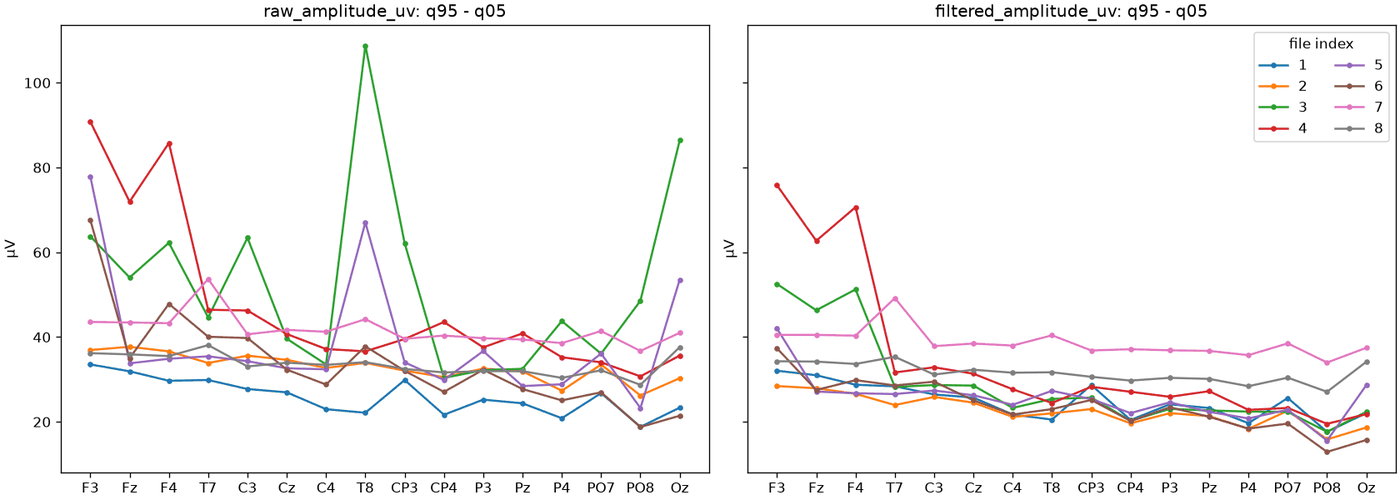

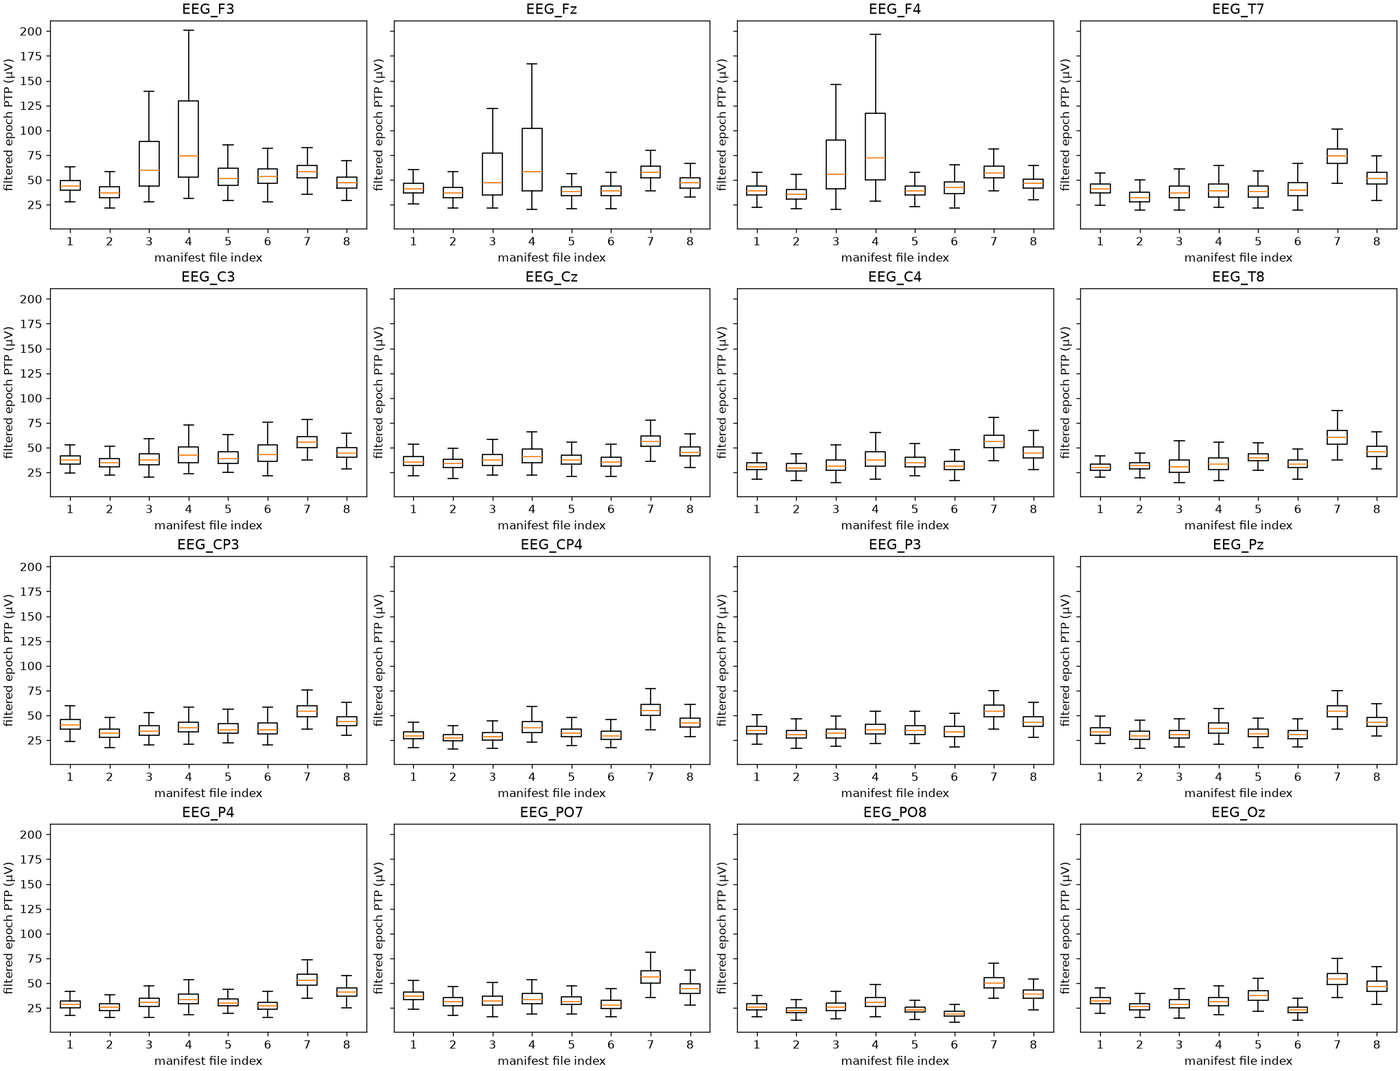

In [6]:
picture('amplitude_distribution.png')
picture('ptp_by_file_channel.png',1350)

In [7]:
display(pd.read_csv(OUT/'ptp_subject_quantiles.csv').head(20))
display(pd.read_csv(OUT/'ptp_session_quantiles.csv').query("channel in ['EEG_Fz','EEG_Pz','EEG_T7']"))
print('原始/滤波连续幅值与epoch PTP分位数：',OUT/'all_distributions.csv')
print('全部epoch×16通道原值：',OUT/'all_ptp.csv')

,subject_id,channel,q05,q25,q50,q75,q95,q99
0,F_03,EEG_C3,27.375486,32.067547,36.048784,40.862347,49.095109,54.293340
1,F_03,EEG_C4,22.680319,26.776781,30.259491,34.216881,40.705569,45.578473
2,F_03,EEG_CP3,25.061326,31.269022,35.946460,41.600772,50.461994,56.653710
3,F_03,EEG_CP4,21.169076,25.175451,28.313798,32.087938,38.616801,42.403972
4,F_03,EEG_Cz,26.123904,31.060132,34.821960,39.281825,47.040135,53.117806
5,F_03,EEG_F3,29.231406,35.502056,40.711998,46.882006,56.395670,63.616611
6,F_03,EEG_F4,26.859925,32.627962,37.080021,42.654383,53.222695,61.286891
7,F_03,EEG_Fz,28.577145,34.492586,39.399014,45.294102,55.736939,61.948313
8,F_03,EEG_Oz,20.232567,25.455093,29.229917,33.249580,39.929428,46.399306
9,F_03,EEG_P3,24.163194,28.847290,32.606972,36.983236,45.345928,50.165043


,subject_id,session_id,channel,q05,q25,q50,q75,q95,q99
7,F_03,SE001,EEG_Fz,32.193945,37.136880,41.135160,46.773655,55.627281,63.554003
13,F_03,SE001,EEG_Pz,25.029932,29.592957,33.511849,37.472137,45.053878,47.783652
14,F_03,SE001,EEG_T7,31.460744,36.864499,40.788428,45.490388,52.834135,58.610977
23,F_03,SE002,EEG_Fz,26.604936,32.055733,36.909627,42.632132,55.799567,60.266552
29,F_03,SE002,EEG_Pz,21.905080,26.040897,29.359948,33.729725,41.365176,45.567827
30,F_03,SE002,EEG_T7,23.120124,27.795760,31.906598,37.435455,46.200240,52.531117
39,F_05,SE001,EEG_Fz,26.488238,34.693412,47.443108,76.890274,106.019090,116.548956
45,F_05,SE001,EEG_Pz,23.261903,26.975137,30.837065,34.963040,41.619707,47.384204
46,F_05,SE001,EEG_T7,25.327409,31.712228,37.101685,43.528282,65.638764,130.004269
55,F_05,SE002,EEG_Fz,29.948496,38.847990,58.140557,101.642873,138.661585,158.349582


原始/滤波连续幅值与epoch PTP分位数： outputs\expanded_pilot\all_distributions.csv
全部epoch×16通道原值： outputs\expanded_pilot\all_ptp.csv


## 5. 独立眨眼候选：共同额区慢变化，而非Fz单峰

正式信号保持不变。独立分支在正式因果信号之后接二阶因果5 Hz低通，取F3/Fz/F4的带符号中位数作为共同额区波形，对其绝对幅值做滞回扫描，允许向上或向下。

达到entry后启动片段；降到exit以下并持续recovery时确认恢复。近邻片段按merge_gap合并。随后检查持续时间、至少两个额区通道的同向幅值与相关性、慢分量PTP占比、峰间距。幅值为峰时额区绝对幅值的中位数；后部为同一时点Pz/PO7/PO8/Oz绝对幅值中位数。额/后比只是支持指标（当前不设硬拒绝门槛）。它不证明来源是眼动，也不能把真实脑电或任务ERP排除在外。

检测函数只接受EEG、采样率、通道名及固定参数，不接受target/non-target，也不根据整份文件估计阈值。

In [8]:
display(pd.Series(parameters['blink_detector'],name='candidate parameter').to_frame())
counts=manifest[['edf_name','site','site_status']].merge(blinks.groupby('edf_name').size().rename('blink_candidates'),on='edf_name',how='left').fillna({'blink_candidates':0})
display(counts)
display(blinks[['edf_name','blink_candidate_id','label','onset_seconds','peak_seconds','offset_seconds','decision_seconds',
                'frontal_amplitude_uv','posterior_amplitude_uv','frontal_posterior_metric','frontal_dominance_support',
                'supporting_channels','slow_ptp_fraction','filter_startup']].head(15))

,candidate parameter
status,unvalidated engineering candidates; fixed para...
frontal_channels,"[EEG_F3, EEG_Fz, EEG_F4]"
posterior_channels,"[EEG_Pz, EEG_PO7, EEG_PO8, EEG_Oz]"
auxiliary_lowpass_hz,5.0
auxiliary_order,2
entry_uv,20.0
exit_uv,10.0
min_frontal_amplitude_uv,25.0
min_support_channels,2
support_peak_fraction,0.5


,edf_name,site,site_status,blink_candidates
0,F_03_SE001_CBCol_Train01.edf,ETSU,inferred,3.0
1,F_03_SE002_CBCol_Train01.edf,ETSU,inferred,6.0
2,F_05_SE001_CBCol_Train02.edf,Duke,inferred,95.0
3,F_05_SE002_CBCol_Train01.edf,Duke,inferred,102.0
4,F_06_SE001_CBCol_Train01.edf,Duke,inferred,2.0
5,F_06_SE002_CBCol_Train01.edf,Duke,inferred,0.0
6,F_20_SE001_CBCol_Train01.edf,ETSU,inferred,6.0
7,F_20_SE002_CBCol_Train01.edf,ETSU,inferred,12.0


,edf_name,blink_candidate_id,label,onset_seconds,peak_seconds,offset_seconds,decision_seconds,frontal_amplitude_uv,posterior_amplitude_uv,frontal_posterior_metric,frontal_dominance_support,supporting_channels,slow_ptp_fraction,filter_startup
0,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0001,CANDIDATE_blink,1.414062,1.800781,2.054688,2.207031,33.624529,4.163563,8.075903,True,EEG_F3;EEG_Fz;EEG_F4,0.854177,True
1,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0002,CANDIDATE_blink,108.761719,108.902344,109.355469,109.507812,27.616694,2.046292,13.495971,True,EEG_F3;EEG_Fz;EEG_F4,0.739490,False
2,F_03_SE001_CBCol_Train01.edf,F_03_SE001_CBCol_Train01_B0003,CANDIDATE_blink,212.421875,212.453125,212.570312,212.722656,25.497460,2.579679,9.883967,True,EEG_F3;EEG_Fz;EEG_F4,0.391186,False
3,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0001,CANDIDATE_blink,0.140625,0.175781,0.261719,0.414062,25.151870,11.893282,2.114796,True,EEG_F3;EEG_Fz;EEG_F4,0.419083,True
4,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0002,CANDIDATE_blink,0.500000,0.546875,0.820312,0.972656,26.479451,9.189250,2.881568,True,EEG_F3;EEG_Fz;EEG_F4,0.438854,True
5,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0003,CANDIDATE_blink,4.191406,4.238281,4.734375,4.886719,27.251595,1.064509,25.600156,True,EEG_F3;EEG_Fz;EEG_F4,0.912801,True
6,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0004,CANDIDATE_blink,87.410156,87.675781,87.984375,88.136719,27.995521,6.716589,4.168116,True,EEG_F3;EEG_Fz;EEG_F4,0.764296,False
7,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0005,CANDIDATE_blink,106.148438,106.207031,106.335938,106.488281,29.884830,5.922814,5.045715,True,EEG_F3;EEG_Fz;EEG_F4,0.417220,False
8,F_03_SE002_CBCol_Train01.edf,F_03_SE002_CBCol_Train01_B0006,CANDIDATE_blink,126.917969,126.941406,127.039062,127.191406,25.636633,1.626763,15.759289,True,EEG_F3;EEG_Fz;EEG_F4,0.437914,False
9,F_05_SE001_CBCol_Train02.edf,F_05_SE001_CBCol_Train02_B0001,CANDIDATE_blink,2.042969,2.226562,2.445312,2.597656,51.829065,0.641293,51.829065,True,EEG_F3;EEG_Fz;EEG_F4,0.830733,True


**延迟解读：**onset/offset是辅助分支上的回溯波形边界；decision_sample为恢复确认与offset后合并等待两者中较晚的样本，检测不会在decision之前输出。辅助滤波还增加频率相关的信号延迟，不能把候选起点当作原始眨眼真实起点，也不能把它当成实时决策时间。

EOF未确认恢复的片段只进入excursion log，不包装为已确认候选。启动期候选可保留绘图，但filter_startup单独标记，不算人工验证中的成功检出。

,count,min,median,max
edf_name,,,,
F_03_SE001_CBCol_Train01.edf,3,0.269531,0.406250,0.605469
F_03_SE002_CBCol_Train01.edf,6,0.238281,0.353516,0.648438
F_05_SE001_CBCol_Train02.edf,95,0.214844,0.402344,1.042969
F_05_SE002_CBCol_Train01.edf,102,0.250000,0.490234,1.152344
F_06_SE001_CBCol_Train01.edf,2,0.242188,0.283203,0.324219
F_20_SE001_CBCol_Train01.edf,6,0.250000,0.500000,0.781250
F_20_SE002_CBCol_Train01.edf,12,0.230469,0.412109,0.812500


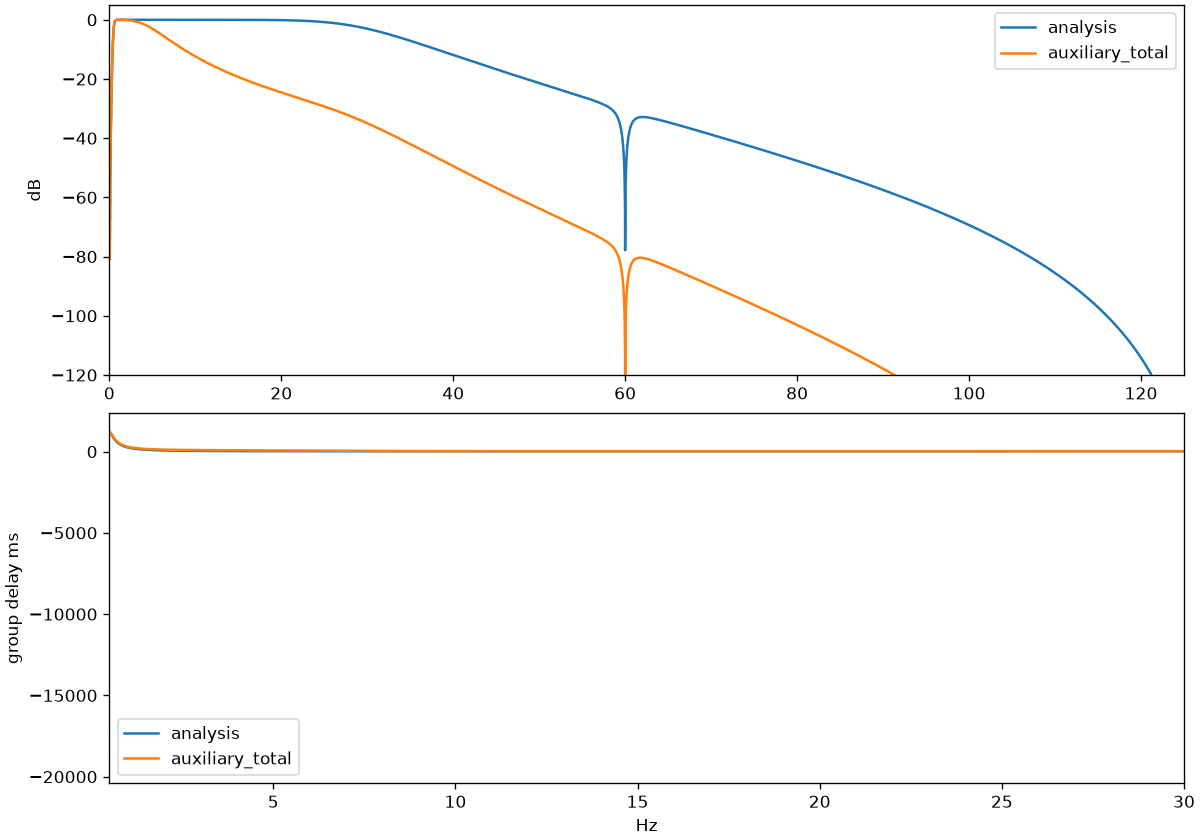

In [9]:
display(blinks.groupby('edf_name').detection_delay_from_peak_seconds.agg(['count','min','median','max']))
picture('causal_branch_responses.png',1000)

## 6. 少量候选与未触发对照片段

每个站点固定取manifest的第一份文件，展示最早的非启动期候选和最早固定网格上无候选的4秒片段，共最多4图；不挑最好看的例子。上行为额区，中行为后部，下行为辅助慢分支。灰竖线为flash，橙区为候选，红虚线为峰，紫点线为最早判定时刻。

“未触发”仅是算法对照，**不等于人工确认正常**。同样，触发也不意味着epoch必须拒绝。

,edf_name,kind,start_seconds,stop_seconds,figure,selection
0,F_05_SE001_CBCol_Train02.edf,candidate,8.304688,12.304688,F_05_SE001_CBCol_Train02_candidate.png,earliest eligible candidate / earliest fixed-g...
1,F_05_SE001_CBCol_Train02.edf,untriggered_unknown,14.000000,18.000000,F_05_SE001_CBCol_Train02_untriggered_unknown.png,earliest eligible candidate / earliest fixed-g...
2,F_03_SE001_CBCol_Train01.edf,candidate,106.902344,110.902344,F_03_SE001_CBCol_Train01_candidate.png,earliest eligible candidate / earliest fixed-g...
3,F_03_SE001_CBCol_Train01.edf,untriggered_unknown,10.000000,14.000000,F_03_SE001_CBCol_Train01_untriggered_unknown.png,earliest eligible candidate / earliest fixed-g...


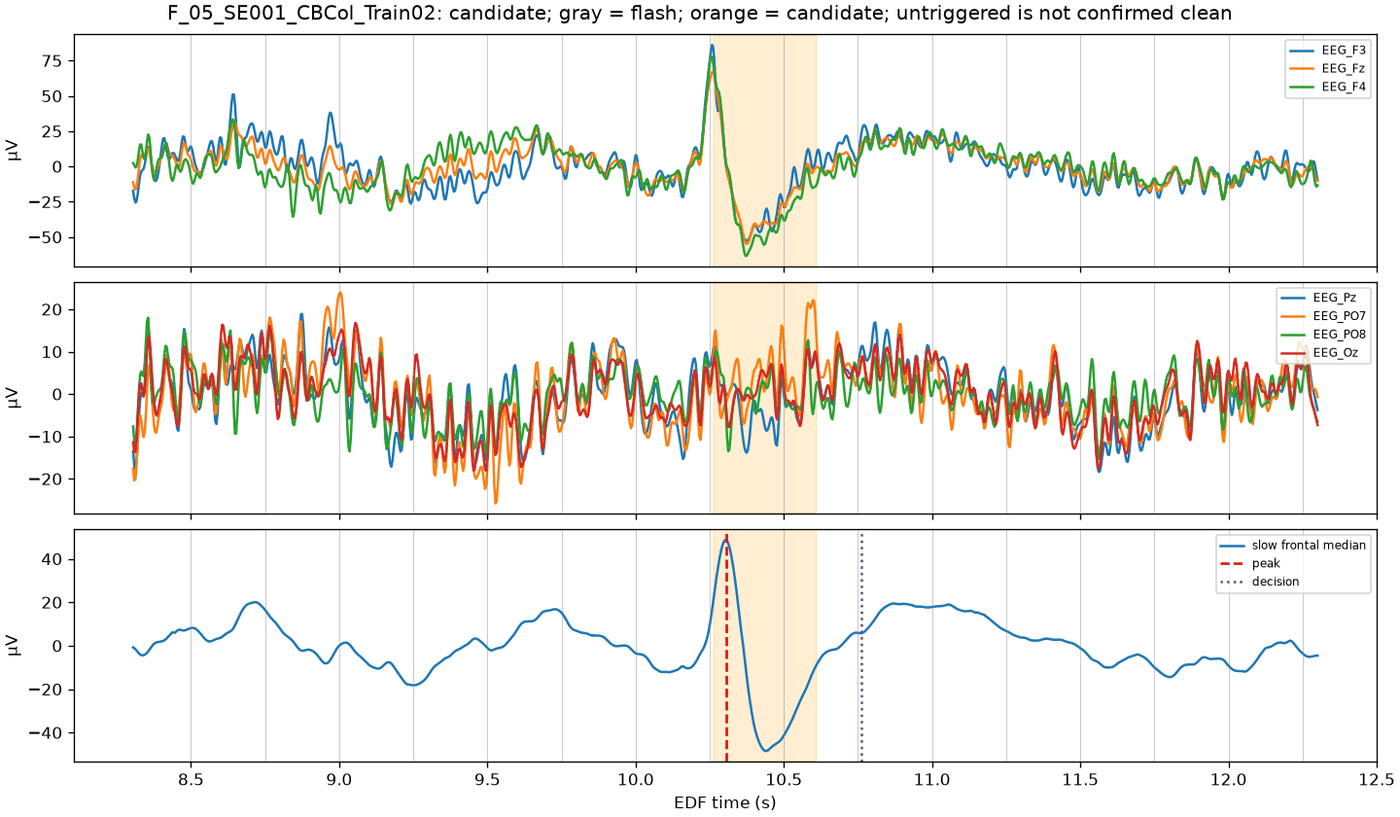

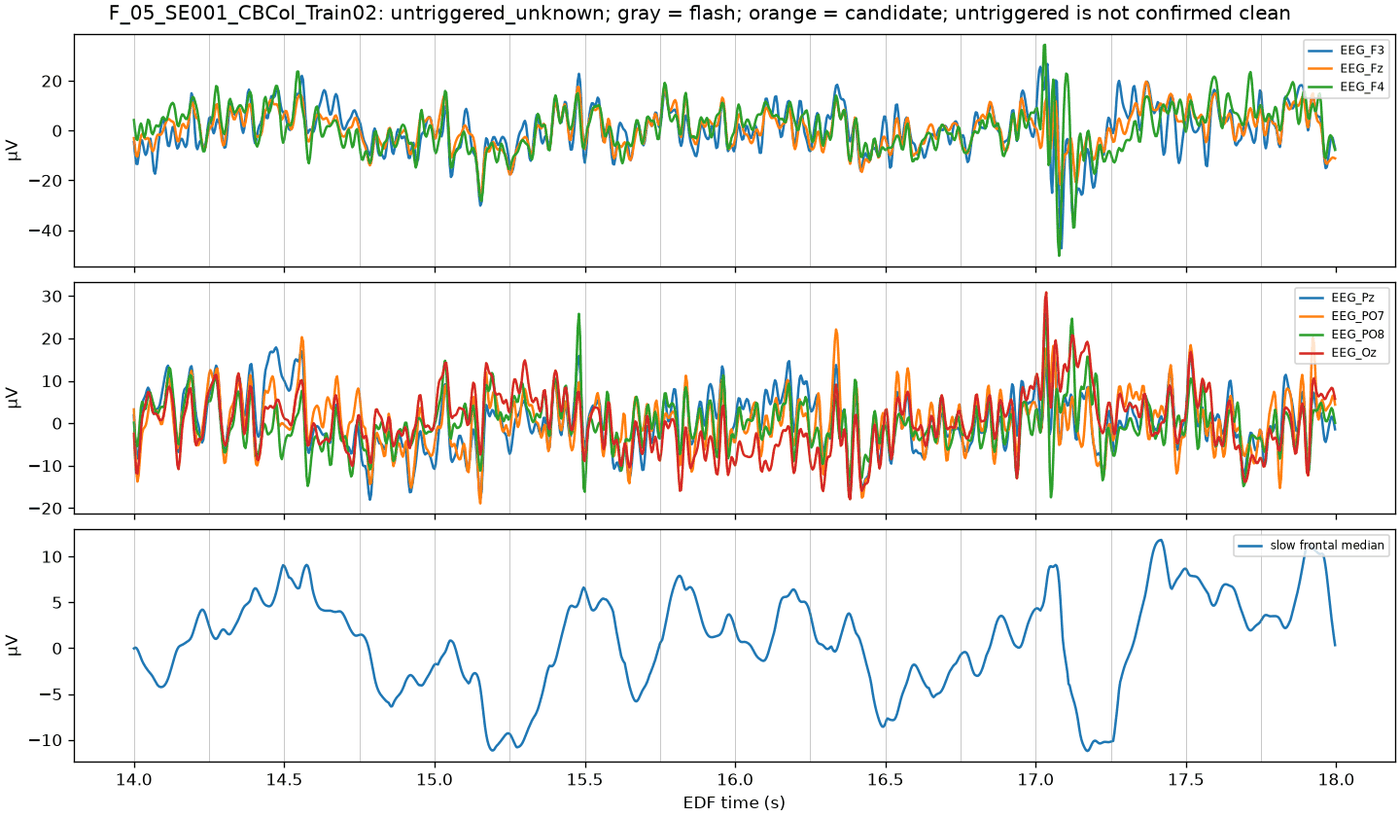

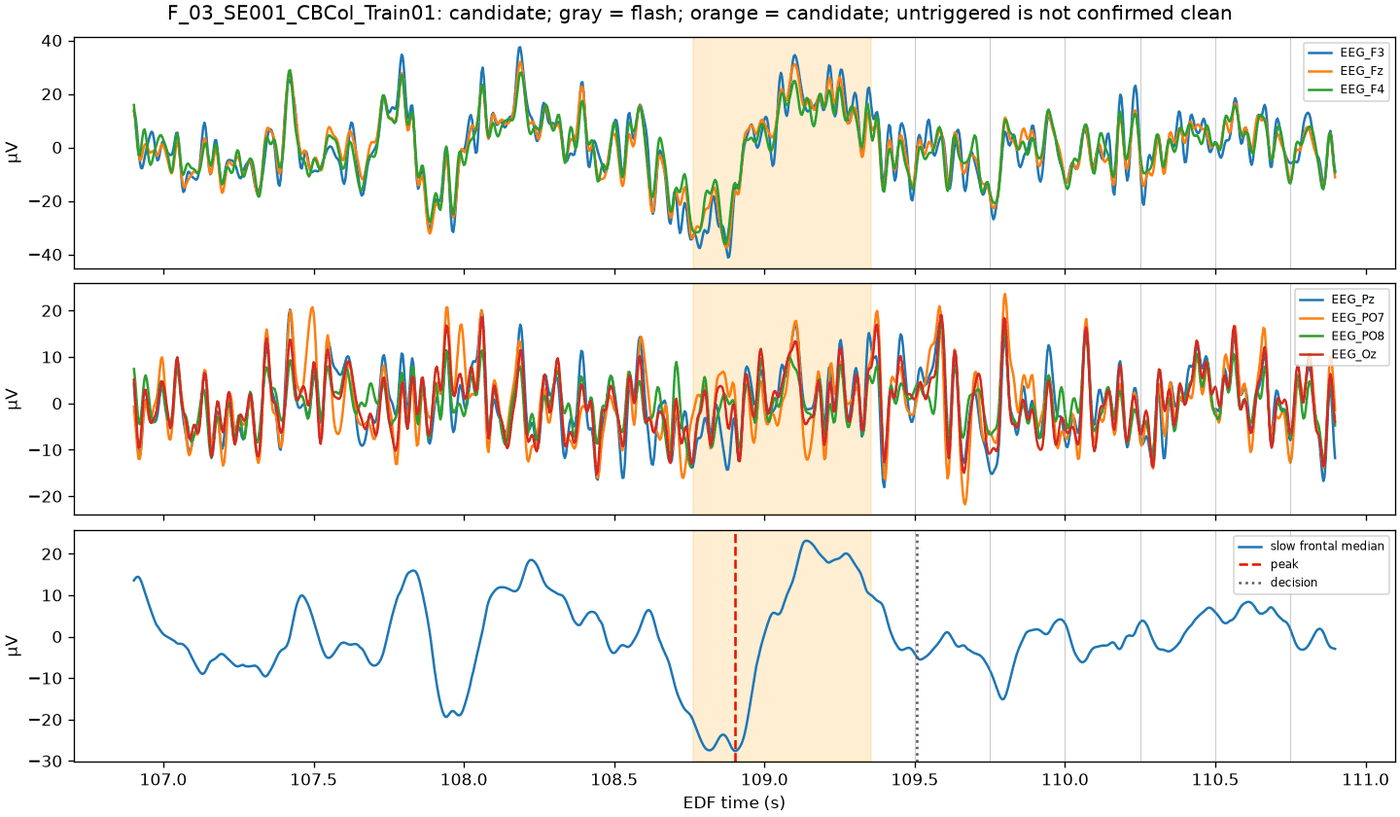

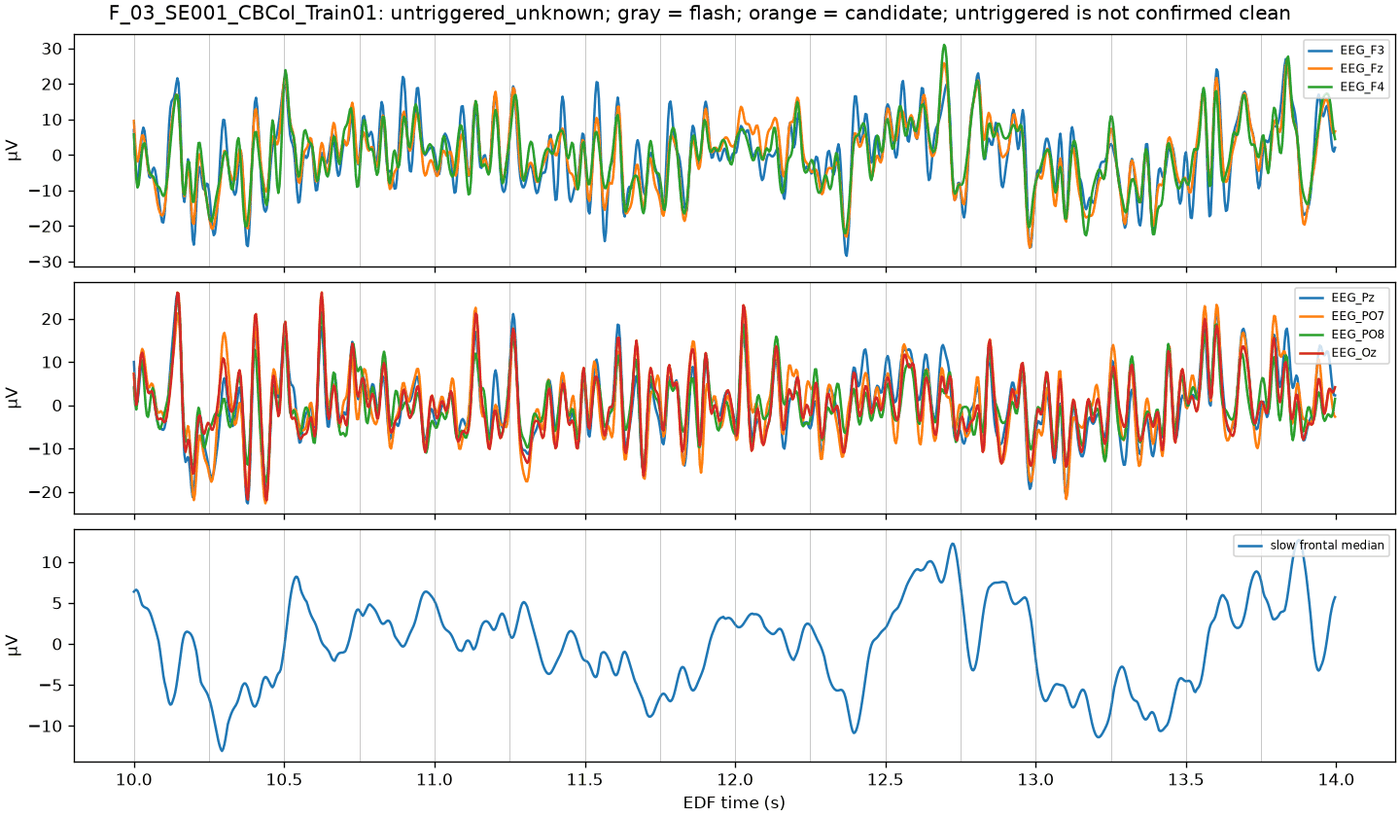

In [10]:
examples=pd.read_csv(OUT/'plotted_examples.csv')
display(examples)
for name in examples.figure:picture(name,1100)

## 7. 原始信号基础故障与逐epoch指标分别保存

原始数据检查NaN/Inf、≥0.25秒常值/全零、0.5秒窗内低变化，以及相邻样本≥100 µV跳变候选。低变化窗步长0.25秒，PTP≤0.5 µV且STD≤0.1 µV；这些是显式工程候选，不是最终标准。不开展心搏、肌电来源分类。

原始候选区间与epoch的关联保留涉及通道和decision时间；完整窗口的原始标记是回顾性关联，模拟时只使用在epoch决定前已经可用的基础标记。持续异常仅报告，绝不删通道、插值或排文件。

In [11]:
if len(quality):
    display(quality.groupby(['edf_name','label']).size().rename('candidates').to_frame())
    display(quality.head(12))
else:print('本轮未检出基础质量候选；不表示已证明无故障。')
persistent=pd.read_csv(OUT/'all_persistent.csv')
display(persistent[persistent.persistent_candidate])
display(events[['edf_name','event_index','flat_candidate','flat_channels','jump_candidate','jump_channels','nonfinite_flag','filter_startup','max_ptp_uv','min_ptp_uv']].groupby('edf_name').agg({'event_index':'size','flat_candidate':'sum','jump_candidate':'sum','nonfinite_flag':'sum','filter_startup':'sum'}))

,,candidates
edf_name,label,
F_05_SE001_CBCol_Train02.edf,CANDIDATE_jump,15
F_05_SE002_CBCol_Train01.edf,CANDIDATE_jump,117
F_06_SE002_CBCol_Train01.edf,CANDIDATE_jump,27


,candidate_id,label,channel,start_sample,stop_sample_exclusive,onset_seconds,offset_seconds,decision_seconds,metric_uv,edf_name,subject_id,session_id,site,site_status
0,Q000001,CANDIDATE_jump,EEG_T7,50,51,0.195312,0.199219,0.195312,104.670,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
1,Q000002,CANDIDATE_jump,EEG_T7,149,150,0.582031,0.585938,0.582031,104.178,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
2,Q000003,CANDIDATE_jump,EEG_T7,288,289,1.125000,1.128906,1.125000,100.608,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
3,Q000004,CANDIDATE_jump,EEG_T7,4503,4504,17.589844,17.593750,17.589844,129.822,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
4,Q000005,CANDIDATE_jump,EEG_T7,39993,39994,156.222656,156.226562,156.222656,139.734,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
5,Q000006,CANDIDATE_jump,EEG_T7,44069,44070,172.144531,172.148438,172.144531,202.710,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
6,Q000007,CANDIDATE_jump,EEG_T7,44070,44071,172.148438,172.152344,172.148438,144.810,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
7,Q000008,CANDIDATE_jump,EEG_T7,46016,46017,179.750000,179.753906,179.750000,128.070,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
8,Q000009,CANDIDATE_jump,EEG_T7,46018,46019,179.757812,179.761719,179.757812,115.986,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred
9,Q000010,CANDIDATE_jump,EEG_T7,46019,46020,179.761719,179.765625,179.761719,220.194,F_05_SE001_CBCol_Train02.edf,F_05,SE001,Duke,inferred


,channel,flat_window_fraction,anomaly_window_fraction,persistent_candidate,reasons,strategy,edf_name,subject_id,session_id,site,site_status


,event_index,flat_candidate,jump_candidate,nonfinite_flag,filter_startup
edf_name,,,,,
F_03_SE001_CBCol_Train01.edf,756,0,0,0,22
F_03_SE002_CBCol_Train01.edf,756,0,0,0,22
F_05_SE001_CBCol_Train02.edf,756,0,11,0,22
F_05_SE002_CBCol_Train01.edf,756,0,5,0,22
F_06_SE001_CBCol_Train01.edf,756,0,0,0,22
F_06_SE002_CBCol_Train01.edf,756,0,46,0,22
F_20_SE001_CBCol_Train01.edf,756,0,0,0,22
F_20_SE002_CBCol_Train01.edf,738,0,0,0,22


## 8. 候选与epoch的多对多关联，不自动拒绝

每条epoch保存has_blink_candidate、ID列表、重叠并集时长、逐通道PTP、flat/jump/nonfinite与原始涉及通道。独立关联表保留一条“候选—epoch”配对，候选可能对应多个重叠epoch。

若候选decision晚于epoch的800 ms等待终点，known_by_epoch_decision=False；未来若要使用该标记控制分类，必须等到earliest_joint_decision_seconds或采用另定的在线政策。本轮只输出事实，不实施该政策。

In [12]:
e=events[events.edf_name.eq(EXAMPLE_EDF)]
display(e[['event_index','character_trial_id','onset_sample','label','has_blink_candidate','blink_candidate_ids','blink_overlap_duration',
           'max_ptp_uv','min_ptp_uv','flat_candidate','jump_candidate','nonfinite_flag','ptp_by_channel']].head(10))
links=pd.read_csv(EDF_DIR/'blink_epoch_links.csv')
display(links.head(15))
ptp=pd.read_csv(EDF_DIR/'epoch_ptp_long.csv')
display(links.merge(ptp,on='event_index').head(20))
assert 'valid_epoch' not in events.columns

,event_index,character_trial_id,onset_sample,label,has_blink_candidate,blink_candidate_ids,blink_overlap_duration,max_ptp_uv,min_ptp_uv,flat_candidate,jump_candidate,nonfinite_flag,ptp_by_channel
1512,0,1,1152,non-target,True,F_05_SE001_CBCol_Train02_B0004,0.246094,75.012507,24.282978,False,False,False,"{""EEG_F3"": 75.01250661230821, ""EEG_Fz"": 53.349..."
1513,1,1,1216,target,True,F_05_SE001_CBCol_Train02_B0004,0.050781,75.410294,22.198886,False,False,False,"{""EEG_F3"": 75.41029360631687, ""EEG_Fz"": 48.132..."
1514,2,1,1280,non-target,False,NaN,0.000000,75.410294,21.933073,False,False,False,"{""EEG_F3"": 75.41029360631687, ""EEG_Fz"": 43.769..."
1515,3,1,1344,non-target,False,NaN,0.000000,50.158511,20.531936,False,False,False,"{""EEG_F3"": 50.1585109349027, ""EEG_Fz"": 36.2079..."
1516,4,1,1408,non-target,False,NaN,0.000000,55.237580,23.022957,False,False,False,"{""EEG_F3"": 48.39888391374101, ""EEG_Fz"": 44.815..."
1517,5,1,1472,non-target,False,NaN,0.000000,55.237580,23.022957,False,False,False,"{""EEG_F3"": 48.39888391374101, ""EEG_Fz"": 44.815..."
1518,6,1,1536,non-target,False,NaN,0.000000,53.451136,27.789518,False,False,False,"{""EEG_F3"": 48.39888391374101, ""EEG_Fz"": 44.310..."
1519,7,1,1600,non-target,False,NaN,0.000000,76.123468,26.368877,False,False,False,"{""EEG_F3"": 41.93982423408146, ""EEG_Fz"": 26.368..."
1520,8,1,1664,non-target,False,NaN,0.000000,122.274310,57.021684,False,False,False,"{""EEG_F3"": 122.27430980098515, ""EEG_Fz"": 90.56..."
1521,9,1,1728,non-target,False,NaN,0.000000,122.274310,57.021684,False,False,False,"{""EEG_F3"": 122.27430980098515, ""EEG_Fz"": 90.56..."


,event_index,blink_candidate_id,overlap_start_sample,overlap_stop_sample_exclusive,overlap_duration_seconds,blink_decision_seconds,known_by_epoch_decision,earliest_joint_decision_seconds
0,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781
1,1,F_05_SE001_CBCol_Train02_B0004,1216,1229,0.050781,4.953125,True,5.550781
2,20,F_05_SE001_CBCol_Train02_B0005,2627,2637,0.039062,10.761719,False,10.761719
3,21,F_05_SE001_CBCol_Train02_B0005,2627,2701,0.289062,10.761719,False,10.761719
4,22,F_05_SE001_CBCol_Train02_B0005,2627,2716,0.347656,10.761719,True,10.800781
5,23,F_05_SE001_CBCol_Train02_B0005,2627,2716,0.347656,10.761719,True,11.050781
6,24,F_05_SE001_CBCol_Train02_B0005,2688,2716,0.109375,10.761719,True,11.300781
7,53,F_05_SE001_CBCol_Train02_B0006,4699,4749,0.195312,18.785156,False,18.785156
8,54,F_05_SE001_CBCol_Train02_B0006,4699,4770,0.277344,18.785156,True,18.800781
9,55,F_05_SE001_CBCol_Train02_B0006,4699,4770,0.277344,18.785156,True,19.050781


,event_index,blink_candidate_id,overlap_start_sample,overlap_stop_sample_exclusive,overlap_duration_seconds,blink_decision_seconds,known_by_epoch_decision,earliest_joint_decision_seconds,channel,ptp_uv
0,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_F3,75.012507
1,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_Fz,53.349501
2,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_F4,44.208998
3,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_T7,53.896278
4,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_C3,52.479189
5,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_Cz,39.141729
6,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_C4,29.247494
7,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_T8,73.744103
8,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_CP3,43.547119
9,0,F_05_SE001_CBCol_Train02_B0004,1166,1229,0.246094,4.953125,True,5.300781,EEG_CP4,26.315106


## 9. 人工annotation与完整检查区间

读取对应CSV和FIF并核对一致性。当前F_05 SE001已有51段疑似眨眼；沿用用户确认将此文件MANUAL_bad_span解释为疑似眨眼，不把其他文件所有bad_span都猜成眨眼。原始标注不重写。

只有在显式reviewed_intervals中完整检查过、且不跨启动期/不确定标记的事件才参与验证。未检查区间不当正常，不把未匹配候选算误报。**当前没有reviewed_intervals，所以漏检和未匹配统计不可评价，相关指标留空。**下面重叠/边界差只作描述，不是检出率。

In [13]:
display(pd.read_csv(OUT/'manual_validation_status.csv'))
display(pd.read_csv(EDF_DIR/'manual_event_comparison.csv').head(15))
display(pd.read_csv(EDF_DIR/'manual_candidate_overlaps.csv').head(15))
display(pd.read_csv(EDF_DIR/'manual_event_epoch_ptp.csv').head(20))

,edf_name,manual_sources,manual_source_consistency,suspected_manual_blinks,complete_reviewed_intervals,reviewed_seconds,evaluated_manual_events,evaluated_candidates,matched_manual_events,unmatched_candidates,missed_manual_events,reviewed_event_recall,reviewed_candidate_match_fraction,validation_status,filter_startup_evaluated_as_blink,ground_truth_generated
0,F_03_SE001_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
1,F_03_SE002_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
2,F_05_SE001_CBCol_Train02.edf,"[""outputs\\artifact_qc\\continuous_manual_qc\\...",agree,51,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
3,F_05_SE002_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
4,F_06_SE001_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
5,F_06_SE002_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
6,F_20_SE001_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False
7,F_20_SE002_CBCol_Train01.edf,[],not_applicable,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,unavailable: no exhaustive reviewed_intervals;...,False,False


,manual_id,start_sec,end_sec,evaluation_eligible,matching_candidate_ids,n_overlap_candidates,evaluation_status
0,F_05_SE001_CBCol_Train02_M0001,1.889938,2.193431,False,F_05_SE001_CBCol_Train02_B0001,1,not_evaluable_sparse_or_boundary_or_startup
1,F_05_SE001_CBCol_Train02_M0002,2.903883,3.248762,False,F_05_SE001_CBCol_Train02_B0002,1,not_evaluable_sparse_or_boundary_or_startup
2,F_05_SE001_CBCol_Train02_M0003,3.828159,4.221321,False,F_05_SE001_CBCol_Train02_B0003,1,not_evaluable_sparse_or_boundary_or_startup
3,F_05_SE001_CBCol_Train02_M0004,10.139447,10.470531,False,F_05_SE001_CBCol_Train02_B0005,1,not_evaluable_sparse_or_boundary_or_startup
4,F_05_SE001_CBCol_Train02_M0005,18.192551,18.499973,False,F_05_SE001_CBCol_Train02_B0006,1,not_evaluable_sparse_or_boundary_or_startup
5,F_05_SE001_CBCol_Train02_M0006,31.747137,32.095549,False,F_05_SE001_CBCol_Train02_B0011,1,not_evaluable_sparse_or_boundary_or_startup
6,F_05_SE001_CBCol_Train02_M0007,37.410534,37.854588,False,F_05_SE001_CBCol_Train02_B0012,1,not_evaluable_sparse_or_boundary_or_startup
7,F_05_SE001_CBCol_Train02_M0008,42.868982,43.121752,False,F_05_SE001_CBCol_Train02_B0015,1,not_evaluable_sparse_or_boundary_or_startup
8,F_05_SE001_CBCol_Train02_M0009,50.760781,50.974606,False,F_05_SE001_CBCol_Train02_B0016,1,not_evaluable_sparse_or_boundary_or_startup
9,F_05_SE001_CBCol_Train02_M0010,52.147195,52.512767,False,F_05_SE001_CBCol_Train02_B0017,1,not_evaluable_sparse_or_boundary_or_startup


,manual_id,blink_candidate_id,overlap_seconds,intersection_over_union,onset_difference_seconds,offset_difference_seconds,evaluation_eligible,interpretation
0,F_05_SE001_CBCol_Train02_M0001,F_05_SE001_CBCol_Train02_B0001,0.150463,0.270921,0.153031,0.251881,False,"suspected blink overlap, never automatic epoch..."
1,F_05_SE001_CBCol_Train02_M0002,F_05_SE001_CBCol_Train02_B0002,0.344879,0.390660,-0.271070,0.266863,False,"suspected blink overlap, never automatic epoch..."
2,F_05_SE001_CBCol_Train02_M0003,F_05_SE001_CBCol_Train02_B0003,0.299446,0.585215,0.093716,0.118523,False,"suspected blink overlap, never automatic epoch..."
3,F_05_SE001_CBCol_Train02_M0004,F_05_SE001_CBCol_Train02_B0005,0.208813,0.444350,0.122271,0.138844,False,"suspected blink overlap, never automatic epoch..."
4,F_05_SE001_CBCol_Train02_M0005,F_05_SE001_CBCol_Train02_B0006,0.144505,0.328225,0.162917,0.132839,False,"suspected blink overlap, never automatic epoch..."
5,F_05_SE001_CBCol_Train02_M0006,F_05_SE001_CBCol_Train02_B0011,0.150236,0.296460,0.198175,0.158357,False,"suspected blink overlap, never automatic epoch..."
6,F_05_SE001_CBCol_Train02_M0007,F_05_SE001_CBCol_Train02_B0012,0.174900,0.146848,0.269154,0.746975,False,"suspected blink overlap, never automatic epoch..."
7,F_05_SE001_CBCol_Train02_M0008,F_05_SE001_CBCol_Train02_B0015,0.098314,0.215963,0.154455,0.202467,False,"suspected blink overlap, never automatic epoch..."
8,F_05_SE001_CBCol_Train02_M0009,F_05_SE001_CBCol_Train02_B0016,0.115231,0.277665,0.098594,0.201175,False,"suspected blink overlap, never automatic epoch..."
9,F_05_SE001_CBCol_Train02_M0010,F_05_SE001_CBCol_Train02_B0017,0.188548,0.422229,0.177024,0.080983,False,"suspected blink overlap, never automatic epoch..."


,manual_id,event_index,channel,ptp_uv,filter_startup,manual_evaluation_eligible
0,F_05_SE001_CBCol_Train02_M0004,20,EEG_F3,107.896891,True,False
1,F_05_SE001_CBCol_Train02_M0004,20,EEG_Fz,88.087007,True,False
2,F_05_SE001_CBCol_Train02_M0004,20,EEG_F4,98.321324,True,False
3,F_05_SE001_CBCol_Train02_M0004,20,EEG_T7,47.453616,True,False
4,F_05_SE001_CBCol_Train02_M0004,20,EEG_C3,50.261446,True,False
5,F_05_SE001_CBCol_Train02_M0004,20,EEG_Cz,35.994466,True,False
6,F_05_SE001_CBCol_Train02_M0004,20,EEG_C4,33.065641,True,False
7,F_05_SE001_CBCol_Train02_M0004,20,EEG_T8,34.184431,True,False
8,F_05_SE001_CBCol_Train02_M0004,20,EEG_CP3,39.436351,True,False
9,F_05_SE001_CBCol_Train02_M0004,20,EEG_CP4,25.597300,True,False


未来人工完整检查文件格式为CSV：edf_name,start_sec,end_sec,review_status；仅显式complete区间进入评价，路径见config。程序不会自行创建ground truth。人工眨眼也仅代表疑似眨眼，不代表相关epoch必须拒绝。

边界差定义为自动onset−人工start、自动offset−人工end。原始人工边界与经过额外因果滤波的候选边界不在相同信号域，差异混合了标注与滤波时序影响，不可直接解释为定位误差。

## 10. PTP只做模拟对照：150/250/350 µV与无上限

all16为全通道对照；example8只展示未来8通道QC的可计算性，**不是已确定的分类输入集合**。每个集合的4个方案基础条件相同：不完整、启动期、非有限、滤波恢复、已可用的原始平线、PTP低于0.5 µV。jump和持续异常只报告，眨眼候选完全不参与would_reject。

no_upper只关闭PTP上限，仍保留其他条件，所以预计保留率可能小于100%。方案只产生would_keep/would_reject，没有实际删数据或选最优规则。

scheme,all16_no_upper,all16_upper_150uv,all16_upper_250uv,all16_upper_350uv
edf_name,,,,
F_03_SE001_CBCol_Train01.edf,0.9709,0.9709,0.9709,0.9709
F_03_SE002_CBCol_Train01.edf,0.9709,0.9709,0.9709,0.9709
F_05_SE001_CBCol_Train02.edf,0.9709,0.9643,0.9709,0.9709
F_05_SE002_CBCol_Train01.edf,0.9709,0.8320,0.9709,0.9709
F_06_SE001_CBCol_Train01.edf,0.9709,0.9590,0.9709,0.9709
F_06_SE002_CBCol_Train01.edf,0.9709,0.9709,0.9709,0.9709
F_20_SE001_CBCol_Train01.edf,0.9709,0.9709,0.9709,0.9709
F_20_SE002_CBCol_Train01.edf,0.9702,0.9702,0.9702,0.9702


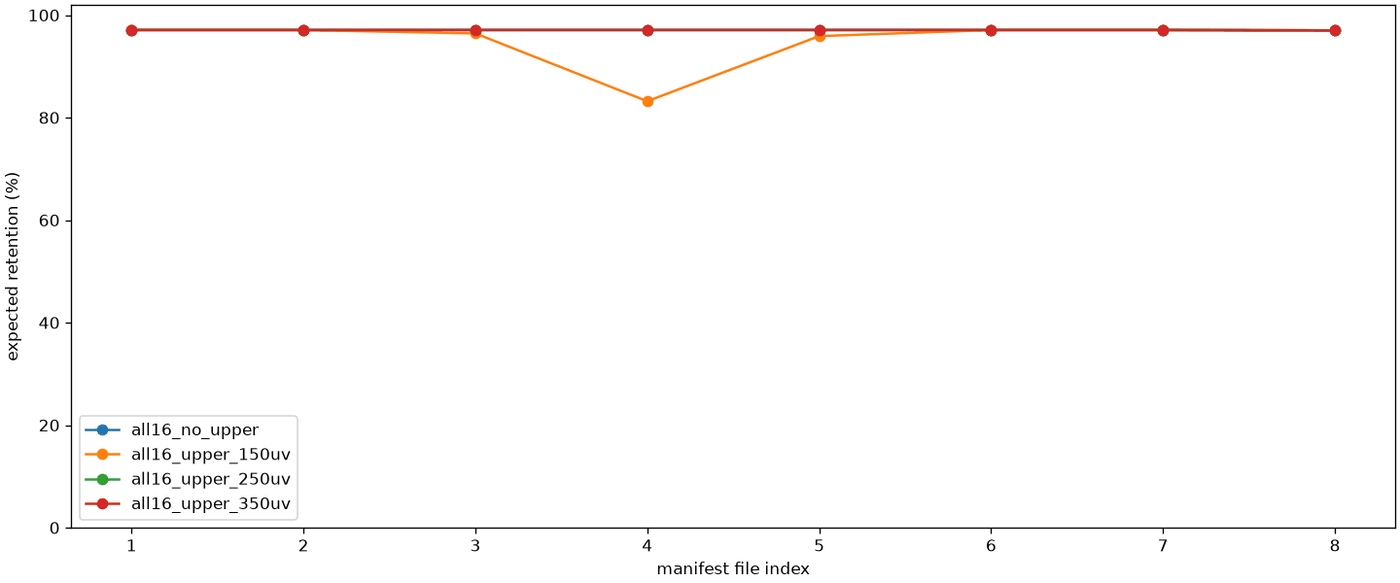

,scheme,edf_name,label,total_flashes,expected_valid_flashes,expected_retention
0,all16_no_upper,F_03_SE001_CBCol_Train01.edf,non-target,672,653,0.971726
1,all16_no_upper,F_03_SE001_CBCol_Train01.edf,target,84,81,0.964286
2,all16_no_upper,F_03_SE002_CBCol_Train01.edf,non-target,672,652,0.970238
3,all16_no_upper,F_03_SE002_CBCol_Train01.edf,target,84,82,0.976190
4,all16_no_upper,F_05_SE001_CBCol_Train02.edf,non-target,672,653,0.971726
5,all16_no_upper,F_05_SE001_CBCol_Train02.edf,target,84,81,0.964286
6,all16_no_upper,F_05_SE002_CBCol_Train01.edf,non-target,672,653,0.971726
7,all16_no_upper,F_05_SE002_CBCol_Train01.edf,target,84,81,0.964286
8,all16_no_upper,F_06_SE001_CBCol_Train01.edf,non-target,672,652,0.970238
9,all16_no_upper,F_06_SE001_CBCol_Train01.edf,target,84,82,0.976190


In [14]:
simulation=pd.read_csv(OUT/'simulation_edf_summary.csv')
display(simulation[simulation.scheme.str.startswith('all16')].pivot(index='edf_name',columns='scheme',values='expected_retention').round(4))
picture('threshold_retention.png')
display(pd.read_csv(OUT/'simulation_label_summary.csv').query("scheme in ['all16_no_upper','all16_upper_150uv','all16_upper_250uv']"))

## 11. 每字符、每刺激集合的有效flash数与主要触发通道

“有效”在本节仅表示假设采用该方案时would_keep，不是最终入模判定。保留所有原始flash，可按任意scheme查看。不因一次异常自动删整个字符。刺激集合为实际亮起的字符状态集合签名，不能冒称固定行/列编号。

In [15]:
character_summary=pd.read_csv(OUT/'simulation_character_summary.csv')
display(character_summary[character_summary.edf_name.eq(EXAMPLE_EDF)&character_summary.scheme.str.startswith('all16')])
group_summary=pd.read_csv(OUT/'simulation_stimulus_group_summary.csv')
display(group_summary[group_summary.edf_name.eq(EXAMPLE_EDF)&group_summary.scheme.eq('all16_upper_150uv')].head(20))
display(pd.read_csv(OUT/'simulation_trigger_channels.csv').sort_values('count',ascending=False).head(20))
print('全部刺激集合计数：',OUT/'simulation_stimulus_group_summary.csv')

,scheme,edf_name,character_trial_id,total_flashes,expected_valid_flashes,expected_retention
12,all16_no_upper,F_05_SE001_CBCol_Train02.edf,1,126,104,0.825397
13,all16_no_upper,F_05_SE001_CBCol_Train02.edf,2,126,126,1.000000
14,all16_no_upper,F_05_SE001_CBCol_Train02.edf,3,126,126,1.000000
15,all16_no_upper,F_05_SE001_CBCol_Train02.edf,4,126,126,1.000000
16,all16_no_upper,F_05_SE001_CBCol_Train02.edf,5,126,126,1.000000
17,all16_no_upper,F_05_SE001_CBCol_Train02.edf,6,126,126,1.000000
60,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,126,104,0.825397
61,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,2,126,126,1.000000
62,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,3,126,126,1.000000
63,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,4,126,126,1.000000


,scheme,edf_name,character_trial_id,stimulus_group_id,total_flashes,expected_valid_flashes,expected_retention
7496,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_00c90bb3a4e4,1,1,1.0
7497,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_023bfec624d0,1,1,1.0
7498,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_030967ab3ccc,1,1,1.0
7499,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_04a840ae86fa,1,1,1.0
7500,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_0ccdbc247b27,1,1,1.0
7501,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_0f74d2c97fb2,1,1,1.0
7502,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_12322ce2c9d4,1,1,1.0
7503,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_1426794e575d,1,1,1.0
7504,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_16b2068ee30d,1,1,1.0
7505,all16_upper_150uv,F_05_SE001_CBCol_Train02.edf,1,observed_188fc389fdd7,1,0,0.0


,edf_name,scheme,channel,count
1,F_05_SE002_CBCol_Train01.edf,all16_upper_150uv,EEG_F3,97
2,F_05_SE002_CBCol_Train01.edf,all16_upper_150uv,EEG_F4,61
3,F_05_SE002_CBCol_Train01.edf,all16_upper_150uv,EEG_Fz,20
5,F_05_SE002_CBCol_Train01.edf,example8_upper_150uv,EEG_Fz,20
7,F_06_SE001_CBCol_Train01.edf,all16_upper_150uv,EEG_F3,9
0,F_05_SE001_CBCol_Train02.edf,all16_upper_150uv,EEG_T7,5
4,F_05_SE002_CBCol_Train01.edf,all16_upper_150uv,EEG_Pz,3
6,F_05_SE002_CBCol_Train01.edf,example8_upper_150uv,EEG_Pz,3


全部刺激集合计数： outputs\expanded_pilot\simulation_stimulus_group_summary.csv


## 12. 产物一致性与结论边界

检查：事件位置和数量不变、16通道逐epoch指标完整、候选decision晚于peak、眨眼候选没有被变为valid_epoch=False、每个方案保存全部事件。源EDF读前/读后hash已记录。测试另外覆盖正负波形对称、拒绝Fz单峰解释、未来数据独立、基础故障与候选不控制模拟。

仍缺少：站点映射的独立证据、108次首字符的采集原因、完整人工复核阴性区间、候选的独立训练集验证、真正刺激组语义说明、最终分类通道与阈值政策。候选数差异不能当作真实眨眼率差异。本轮不确定个体化阈值，不声称候选有效。

In [16]:
assert audit.helper_onsets_match.all() and audit.helper_exact_label_mismatch.eq(0).all()
assert (events.onset_sample==events.original_event_sample).all()
assert 'valid_epoch' not in events.columns
assert (blinks.decision_seconds>=blinks.offset_seconds).all()
assert (blinks.decision_seconds>blinks.peak_seconds).all()
checks=[]
for _,r in manifest.iterrows():
    folder=OUT/Path(r.edf_name).stem
    rec=json.loads((folder/'processing_record.json').read_text())
    p=pd.read_csv(folder/'epoch_ptp_long.csv')
    s=pd.read_csv(folder/'threshold_simulation_epochs.csv')
    assert rec['source_sha256_before']==rec['source_sha256_after']
    assert p.groupby('event_index').size().eq(16).all()
    assert s.groupby('scheme').size().eq(rec['n_epochs']).all()
    with np.load(folder/'epochs_all.npz') as a:
        assert a['eeg_v'].shape==(rec['n_epochs'],16,rec['epoch_samples'])
    checks.append({'edf_name':r.edf_name,'epochs':rec['n_epochs'],'integrity':'PASS'})
display(pd.DataFrame(checks))

,edf_name,epochs,integrity
0,F_03_SE001_CBCol_Train01.edf,756,PASS
1,F_03_SE002_CBCol_Train01.edf,756,PASS
2,F_05_SE001_CBCol_Train02.edf,756,PASS
3,F_05_SE002_CBCol_Train01.edf,756,PASS
4,F_06_SE001_CBCol_Train01.edf,756,PASS
5,F_06_SE002_CBCol_Train01.edf,756,PASS
6,F_20_SE001_CBCol_Train01.edf,756,PASS
7,F_20_SE002_CBCol_Train01.edf,738,PASS


---

## 附录：bigp3bci_causal_preprocessing_pilot

# 因果滤波与自动 epoch QC：pilot 结果逐步解读

本 notebook **读取已经保存的预处理产物**，不重写 EDF，也不重新选择阈值。按“数据来源 → 滤波 → 连续通道质量 → epoch → 拒绝 → ERP”逐步核查。

Duke 为 F_05_SE001_CBCol_Train02，ETSU 为 F_03_SE001_CBCol_Train01。站点对应关系沿用 notebook 02 的**推断映射**，不是新增确认结果。每站仅一份训练文件，因此图形用于开发验证，不能据此确定最终阈值或推断全部受试者。

每个步骤先说明图表回答的问题，再输出结果及解释。可直接查看已保存的输出，也可在 `bigp3bci` 环境中 Run All。若需重跑预处理，先执行 `scripts/run_causal_pilot.py`。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

# 支持从仓库根目录或 notebooks 目录启动。
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/causal_pilot.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('请从项目目录或其 notebooks 子目录启动。')
OUT = ROOT / 'outputs' / 'causal_pilot'
FILES = {'Duke': 'F_05_SE001_CBCol_Train02', 'ETSU': 'F_03_SE001_CBCol_Train01'}
records = {site: json.loads((OUT / stem / 'processing_record.json').read_text(encoding='utf-8'))
           for site, stem in FILES.items()}
tables = {site: pd.read_csv(OUT / stem / 'epoch_metadata_quality.csv',
                          dtype={'valid_epoch': 'boolean', 'classification_eligible': 'boolean'})
          for site, stem in FILES.items()}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
def show_saved(site, image_name, width=1250):
    display(Markdown(f'**{site}（站点推断） · {FILES[site]}**'))
    display(Image(filename=str(OUT / FILES[site] / image_name), width=width))
def read_table(site, name):
    return pd.read_csv(OUT / FILES[site] / name, keep_default_na=False)
print('产物目录：', OUT)

产物目录： outputs\causal_pilot


## 1. 先确认输入和处理范围

下表检查：是否只处理 16 个 EEG 通道、采样率与连续样本数、epoch 样本数，以及采集时已有的滤波。

**采集滤波**来自 EDF 原始 header；**新增滤波**是本次执行的数字处理。即便采集端已做类似滤波，两份文件仍使用相同新增流程。相同新增流程不保证两站原始频响完全一致。

In [2]:
rows=[]
for site, r in records.items():
    acquisition = sorted({v for k,v in r['acquisition_prefilter'].items() if k.startswith('EEG_')})
    rows.append({'site_inferred': site, 'edf': FILES[site], 'EEG_channels': len(r['channels']),
                 'sfreq_Hz': r['sfreq'], 'continuous_samples': r['n_samples'],
                 'epoch_samples': r['epoch_samples'], 'acquisition_prefilter': '; '.join(acquisition),
                 'added_filter': '60 Hz notch → 0.5–30 Hz causal SOS',
                 'file_needs_channel_policy': r['file_needs_channel_policy']})
display(pd.DataFrame(rows))
display(pd.DataFrame(records['Duke']['config']['filter'].items(), columns=['parameter', 'value']))

,site_inferred,edf,EEG_channels,sfreq_Hz,continuous_samples,epoch_samples,acquisition_prefilter,added_filter,file_needs_channel_policy
0,Duke,F_05_SE001_CBCol_Train02,16,256.0,55808,205,HP:0.1Hz LP:60Hz N:60Hz,60 Hz notch → 0.5–30 Hz causal SOS,False
1,ETSU,F_03_SE001_CBCol_Train01,16,256.0,55808,205,HP:0.5Hz LP:30Hz NHP:58Hz NLP:62Hz,60 Hz notch → 0.5–30 Hz causal SOS,False


,parameter,value
0,family,butter
1,order,4
2,notch_hz,60.0
3,notch_q,30.0
4,band_hz,"[0.5, 30.0]"
5,initialization,steady_first_sample
6,chunk_seconds,1.0
7,startup_seconds,10.0


**如何理解：**Duke header 为 HP 0.1 Hz / LP 60 Hz / notch 60 Hz；ETSU 为 HP 0.5 Hz / LP 30 Hz / notch 58–62 Hz。新增滤波为 Q=30 的二阶 notch，随后是原型四阶 Butterworth 带通（带通总八阶）。这是明确记录的工程候选，**不是 BCI2000 的精确复现**。每份 EDF 单独初始化，内部逐块保留滤波状态。

## 2. 实际滤波器的频响与时间延迟

上图显示各频率被保留或衰减多少：0 dB 表示幅度基本保留，−20 dB 表示幅度约变为 1/10。0.5 Hz 以下、30 Hz 以上衰减，60 Hz 还叠加 notch。

下图是群延迟：因果滤波的延迟随频率变化。不能把它解释成所有 EEG 都晚了固定毫秒数。两站新增滤波器相同，因此展示一份设计响应，并列出代表频率的延迟。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

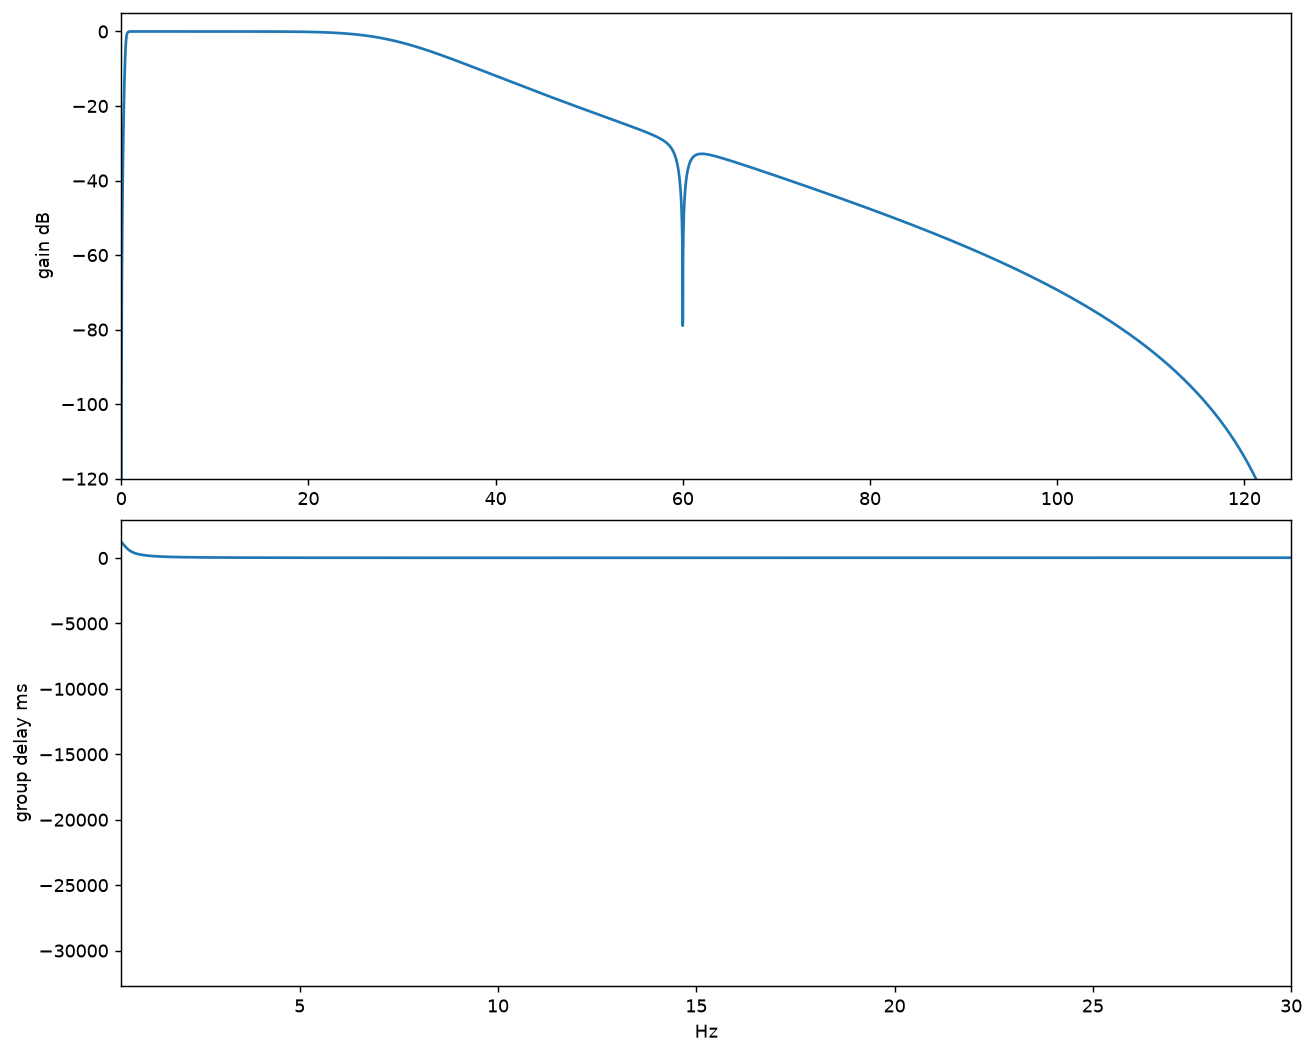

,frequency_Hz,gain_dB,group_delay_ms
0,0.5,-3.084,1218.630
1,1.0,-0.011,251.622
2,5.0,-0.000,22.095
3,10.0,-0.000,16.422
4,20.0,-0.114,18.920
5,30.0,-3.013,22.406
6,60.0,-78.954,-31089.086


In [3]:
show_saved('Duke', 'filter_response.png', 1000)
response = pd.read_csv(OUT / FILES['Duke'] / 'filter_response.csv')
sample_response=[]
for hz in [0.5, 1, 5, 10, 20, 30, 60]:
    v=response.iloc[(response.frequency_hz-hz).abs().argmin()]
    sample_response.append({'frequency_Hz': hz, 'gain_dB': v.gain_db,
                            'group_delay_ms': v.group_delay_seconds * 1000})
display(pd.DataFrame(sample_response).round(3))

**如何理解：**例如 10 Hz 约延迟 16.4 ms，1 Hz 约延迟 251.6 ms；这些是对应频率的群延迟，不是 ERP 峰值的统一修正量。notch 附近幅度极小，其数值群延迟不适合解释被保留信号的时序。**事件 onset 保持原样，没有按延迟移动**。

## 3. 逐通道与平均 PSD：滤波改变了哪些频率？

蓝线是滤波前，橙线是因果滤波后。纵轴为绝对 PSD：`dB(µV²/Hz)`；不是每条曲线单独归一化。每份图内所有通道共享坐标，60 Hz 用竖线标出。最后一格先在线性功率域平均通道，再转 dB。

重点看 30 Hz 以上和 60 Hz 是否进一步衰减；不要因原始 60 Hz 已有凹口就判断新增 notch 未执行。原始 EDF 本身可能已带采集滤波。Welch PSD 使用 4 秒窗，频率分辨率为 0.25 Hz；全文件 PSD 只是开发诊断，不参与测试阈值估计。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

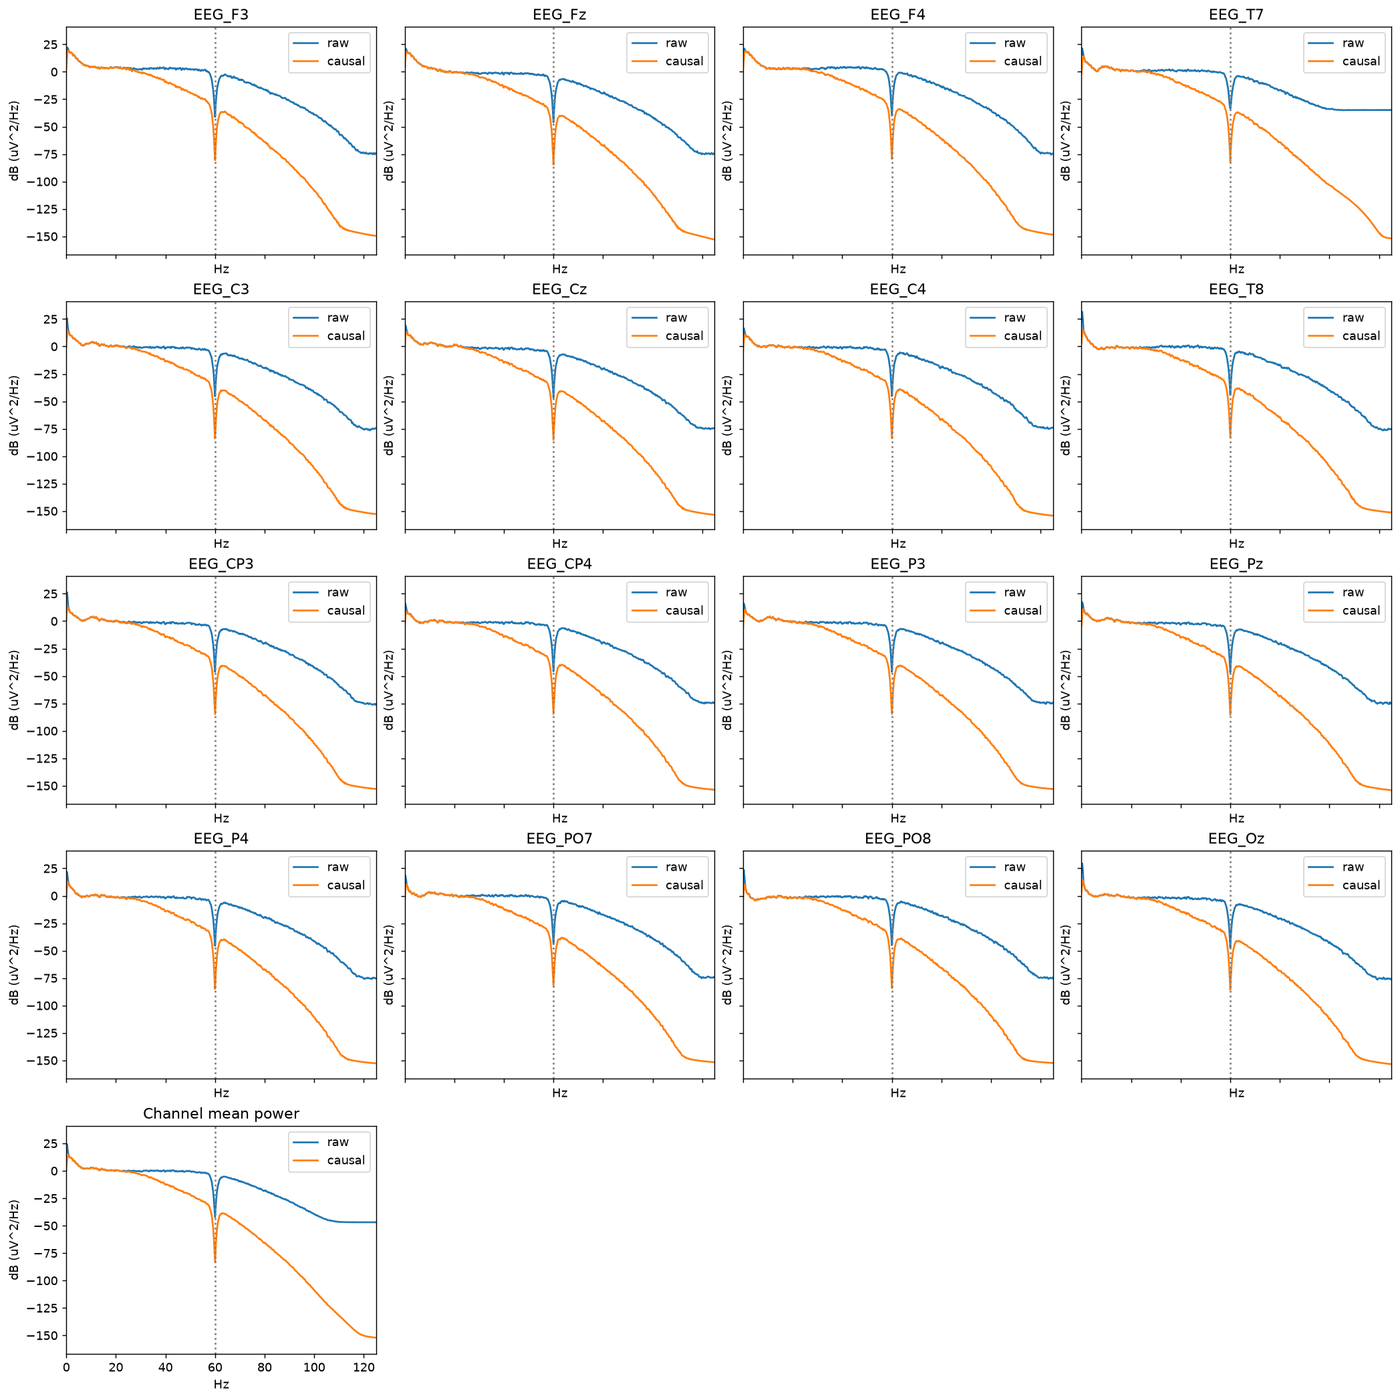

In [4]:
show_saved('Duke', 'psd.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

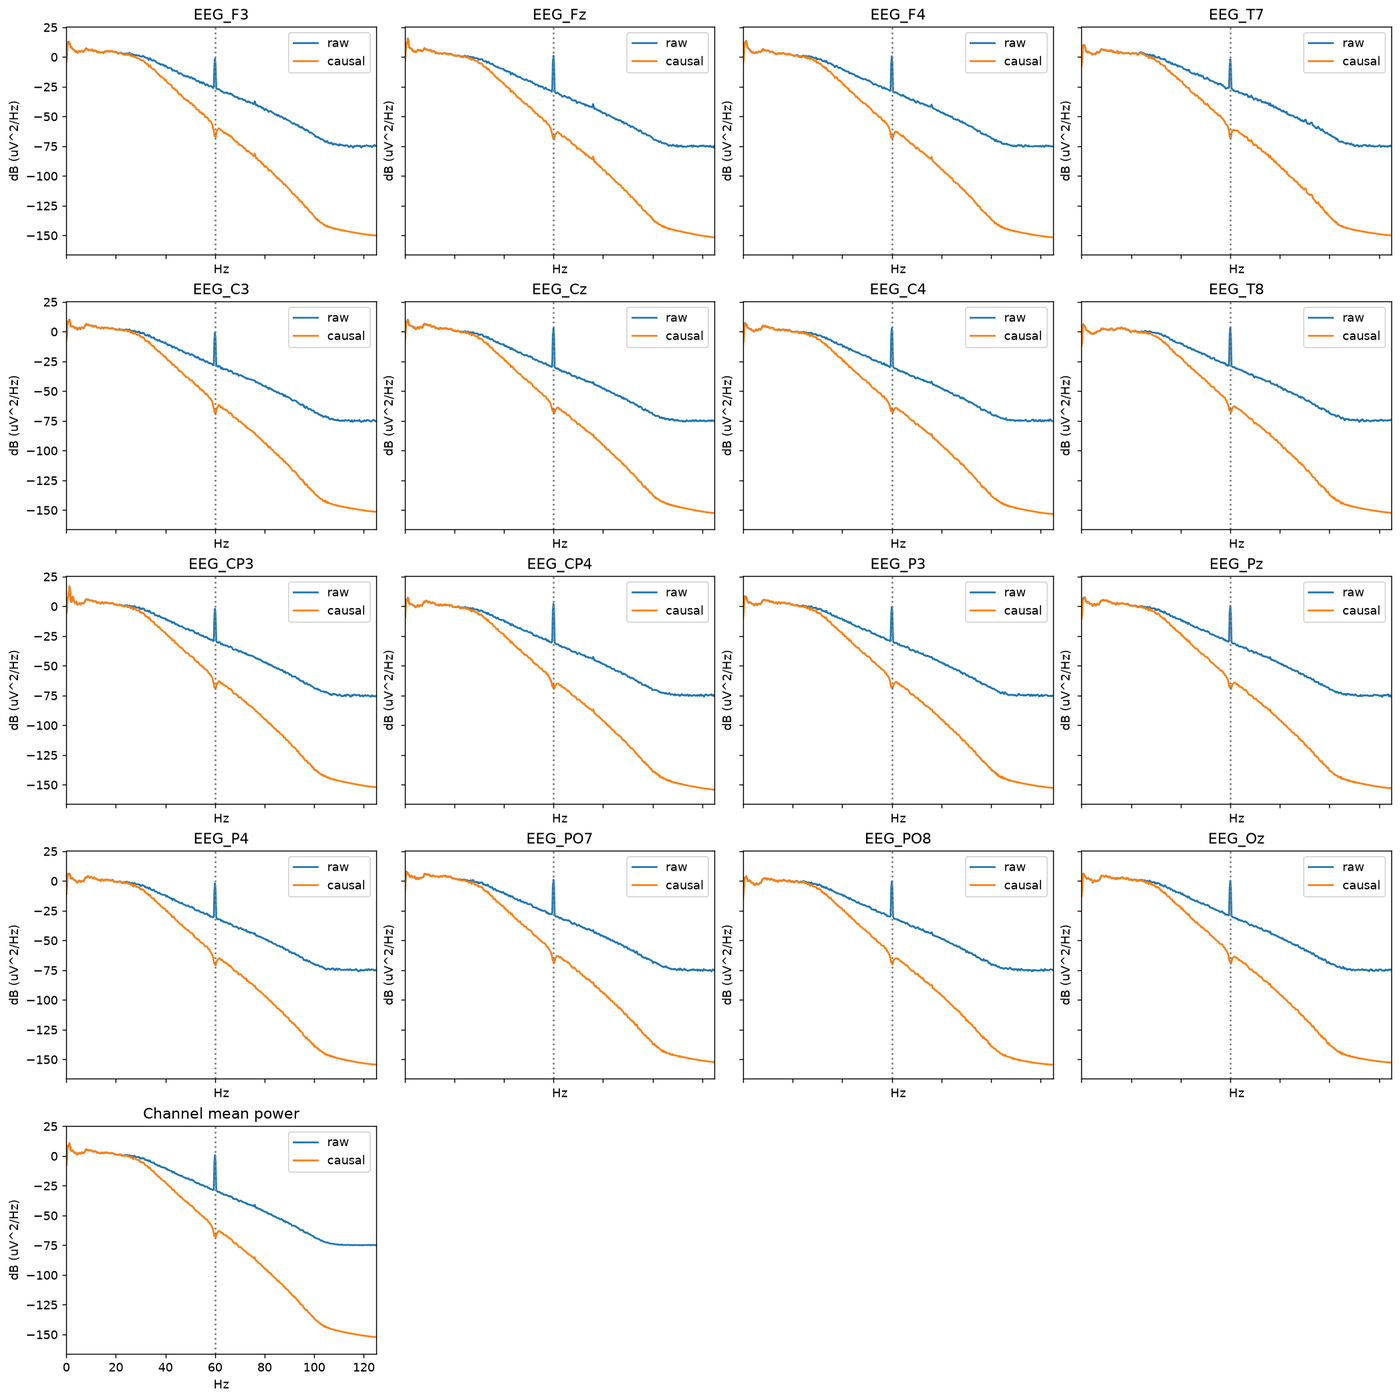

In [5]:
show_saved('ETSU', 'psd.png')

**低频放大图：**下面专看 0–3 Hz 的平均 PSD。低频衰减受原始采集滤波、有限窗分辨率和文件中的瞬变影响，不能只凭一个频点估计滤波器截止频率；截止特性应结合步骤 2 的设计响应。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

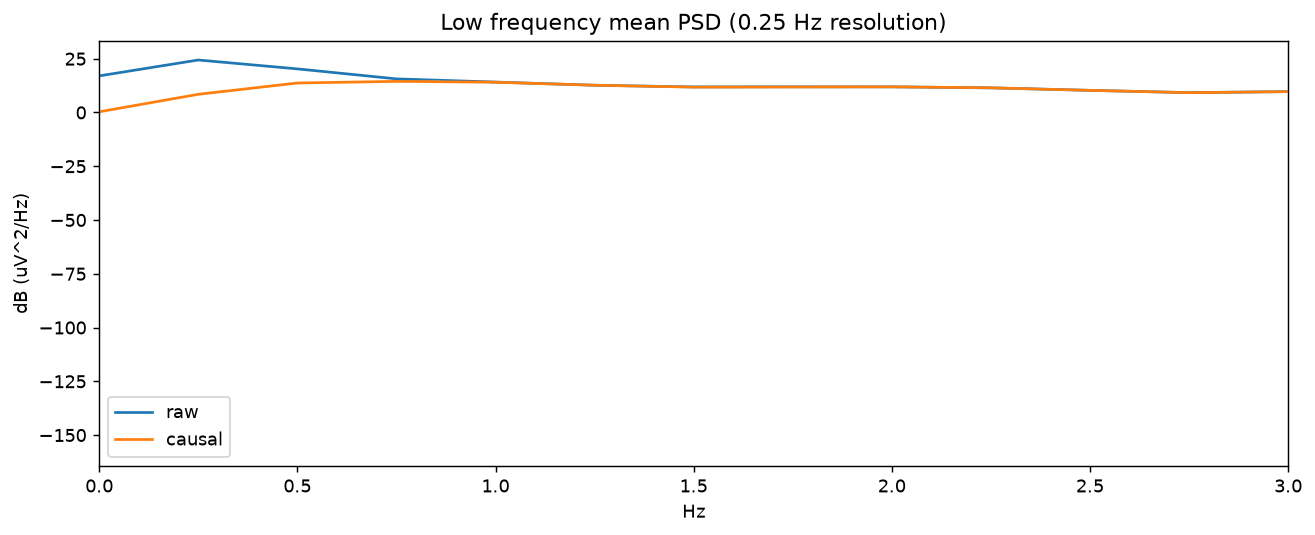

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

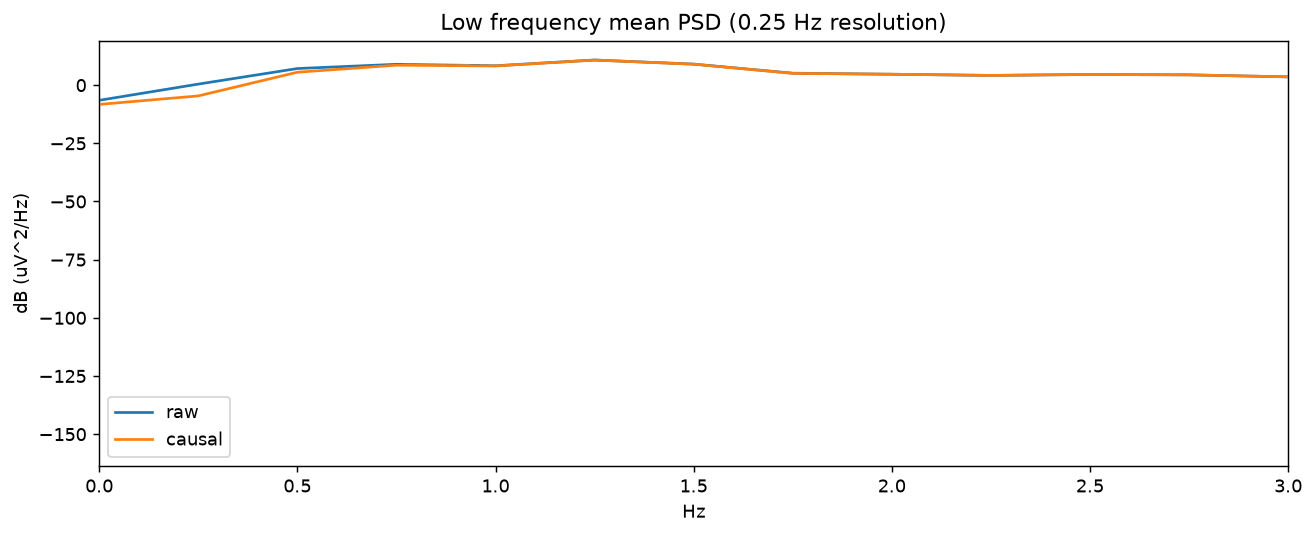

In [6]:
for site in FILES:
    show_saved(site, 'psd_low_frequency.png', 1000)

## 4. 同时间、同纵轴的波形：启动、普通片段、瞬变附近

每格蓝/橙曲线叠加在同一纵轴，单位 µV，横轴为 EDF 起点后的秒数；同一格内不改变显示比例。通道间可以有不同纵轴范围，因此比较滤波前后时应在同一格内观察。

- **startup**：文件最初 10 秒，检查初始化造成的过渡。
- **signal**：固定时间片段，观察慢漂移和快速成分变化。
- **transient**：原始 EEG 最大相邻样本跳变附近，观察瞬变后的过冲、振荡和恢复。这是回顾性画图选择，不是在线异常判定。

橙线仍可能有大幅瞬变；滤波不等于去除所有伪迹。图中相位错位是因果滤波预期行为，不应为让曲线对齐而移动事件。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

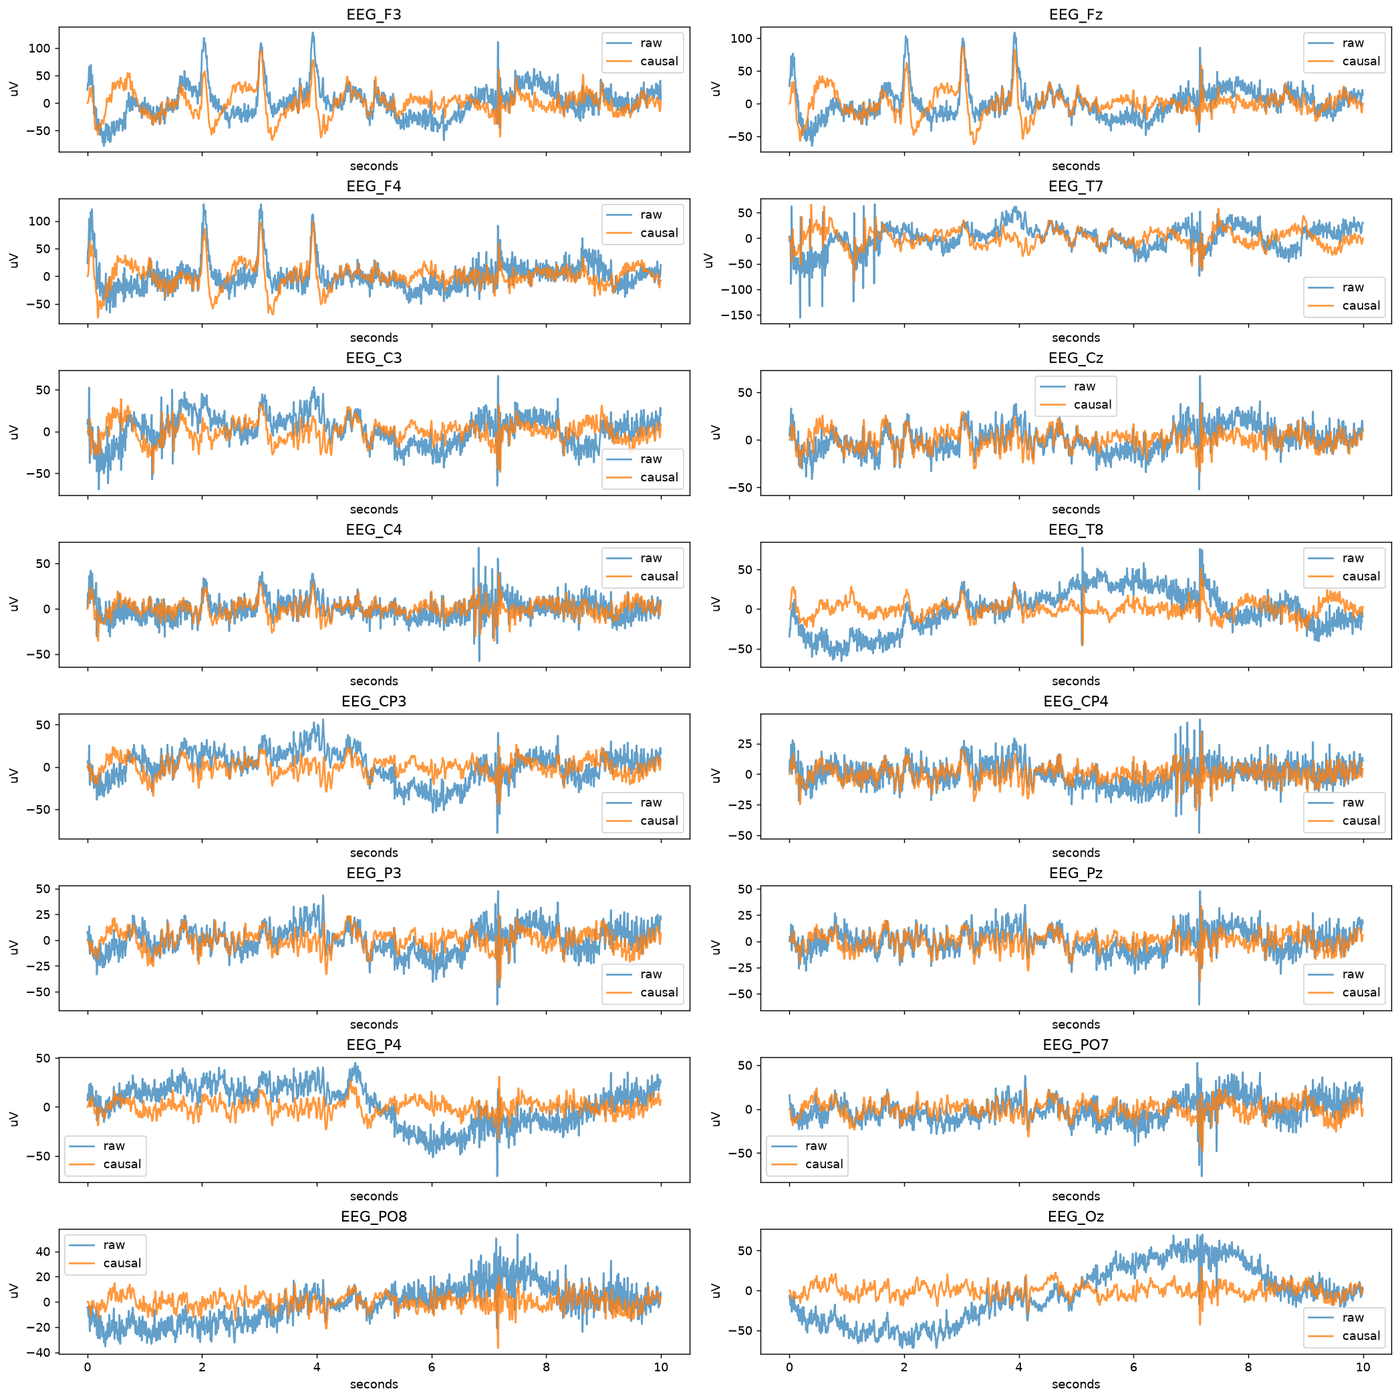

In [7]:
show_saved('Duke', 'waveform_startup.png')

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

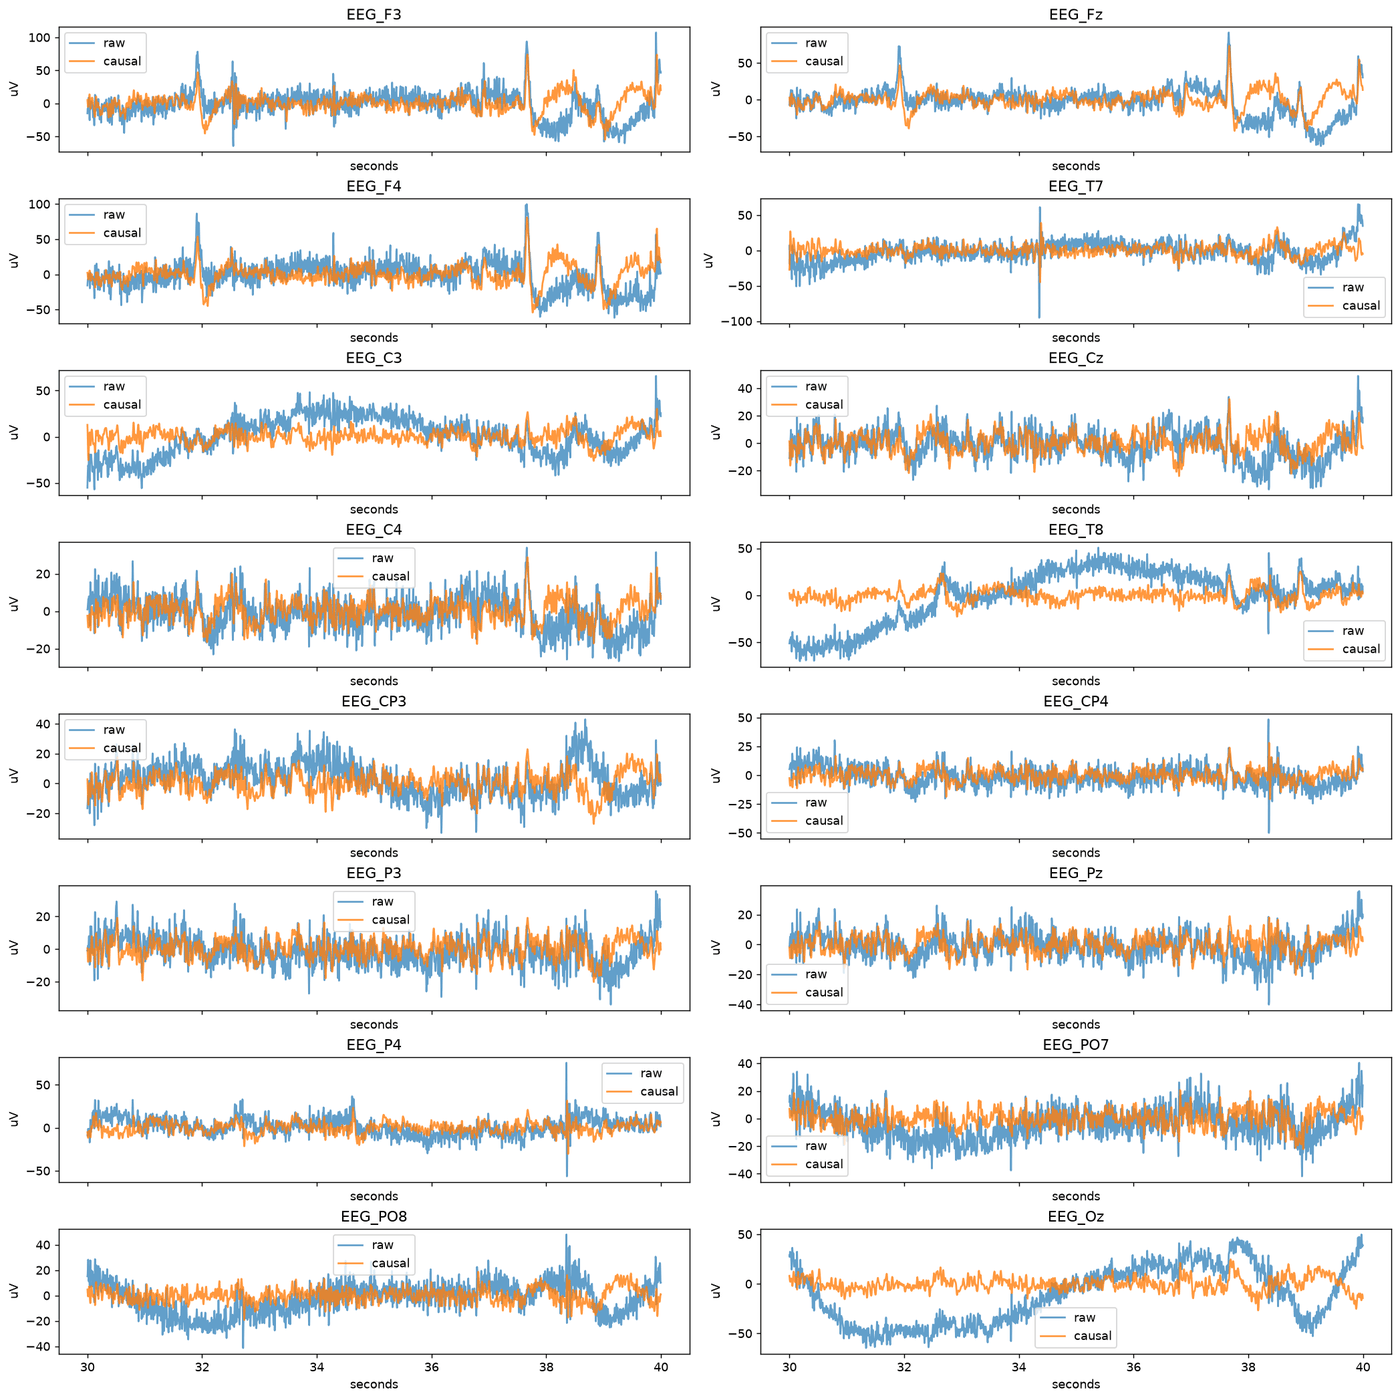

In [8]:
show_saved('Duke', 'waveform_signal.png')

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

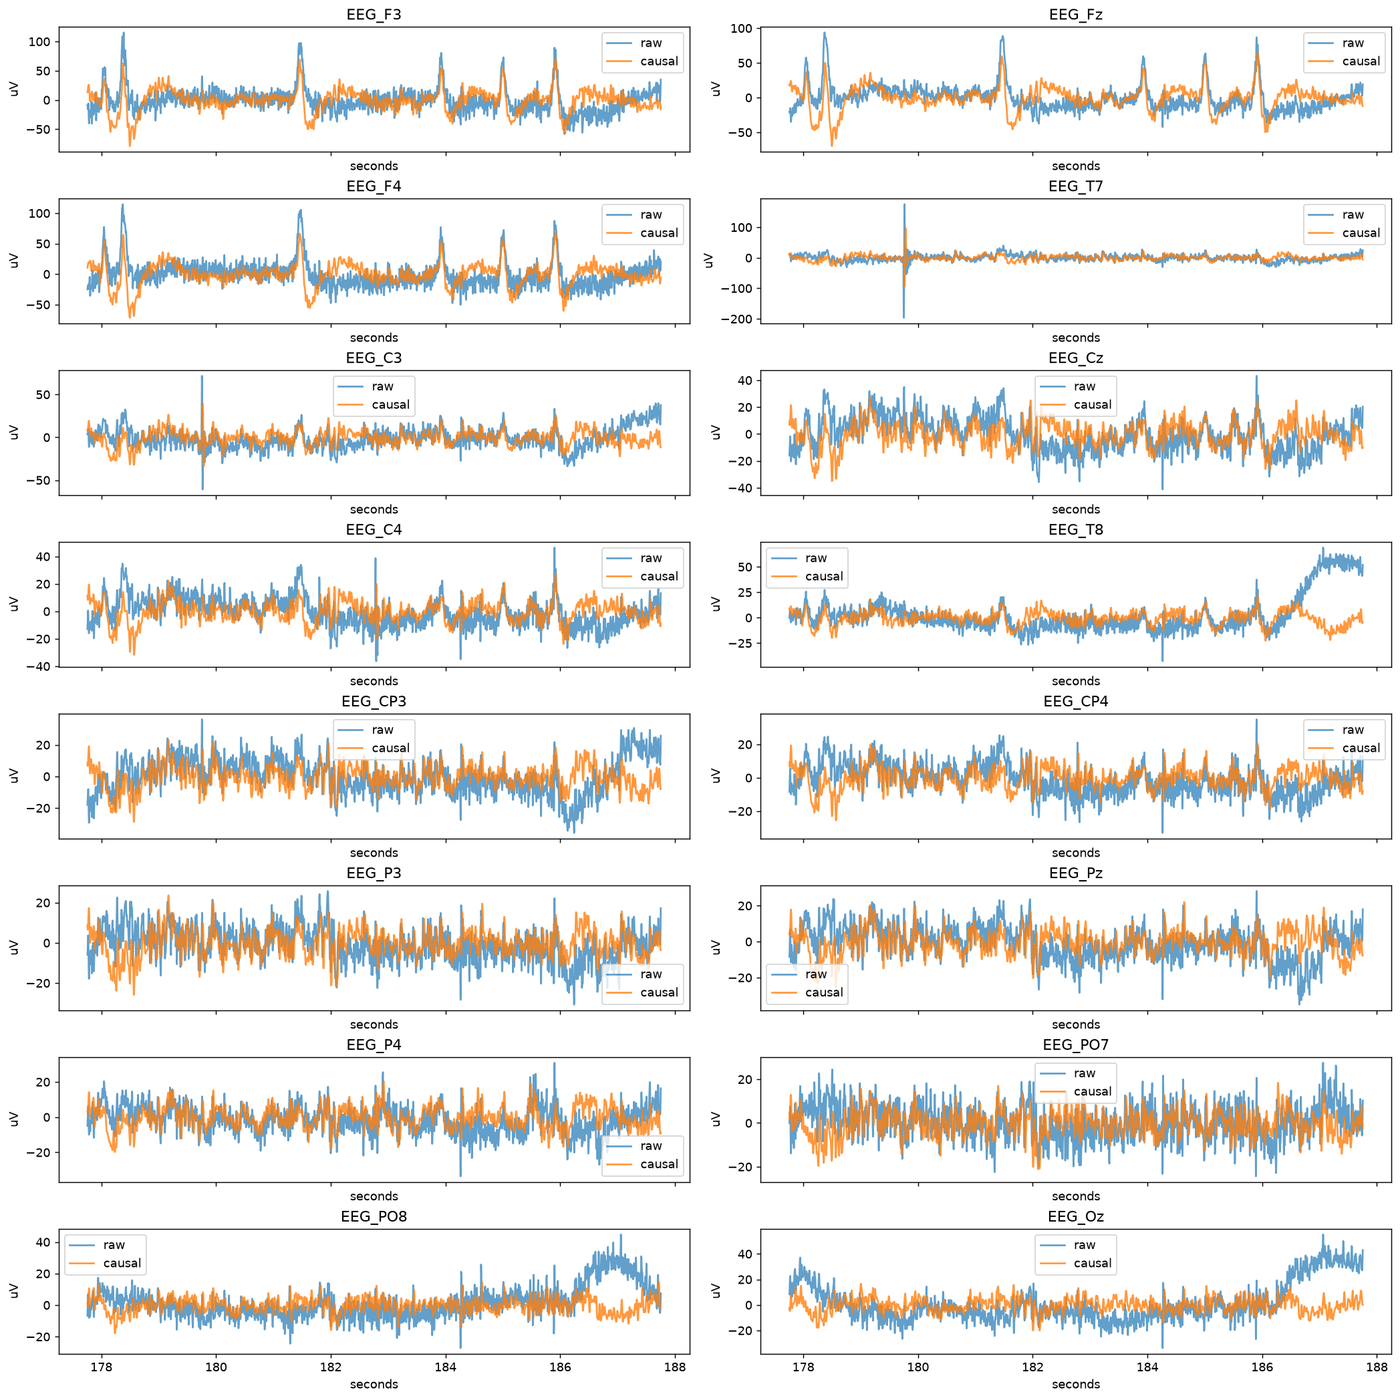

In [9]:
show_saved('Duke', 'waveform_transient.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

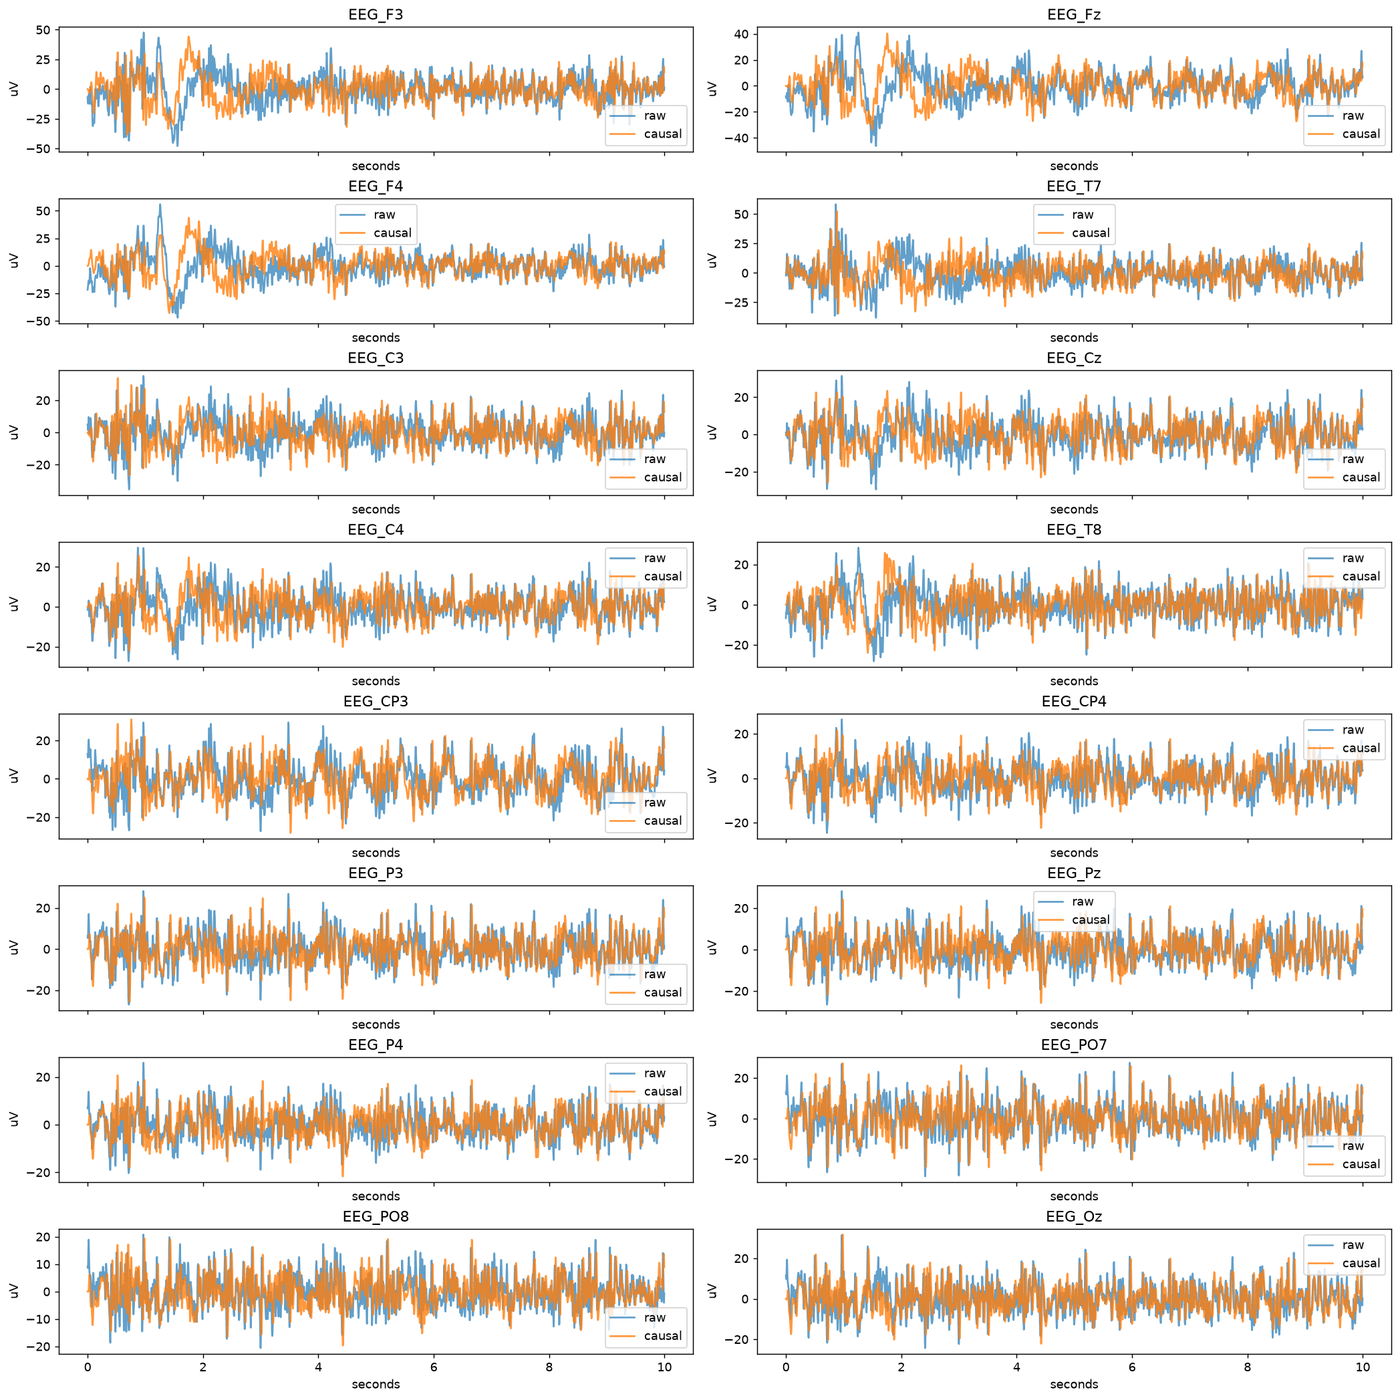

In [10]:
show_saved('ETSU', 'waveform_startup.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

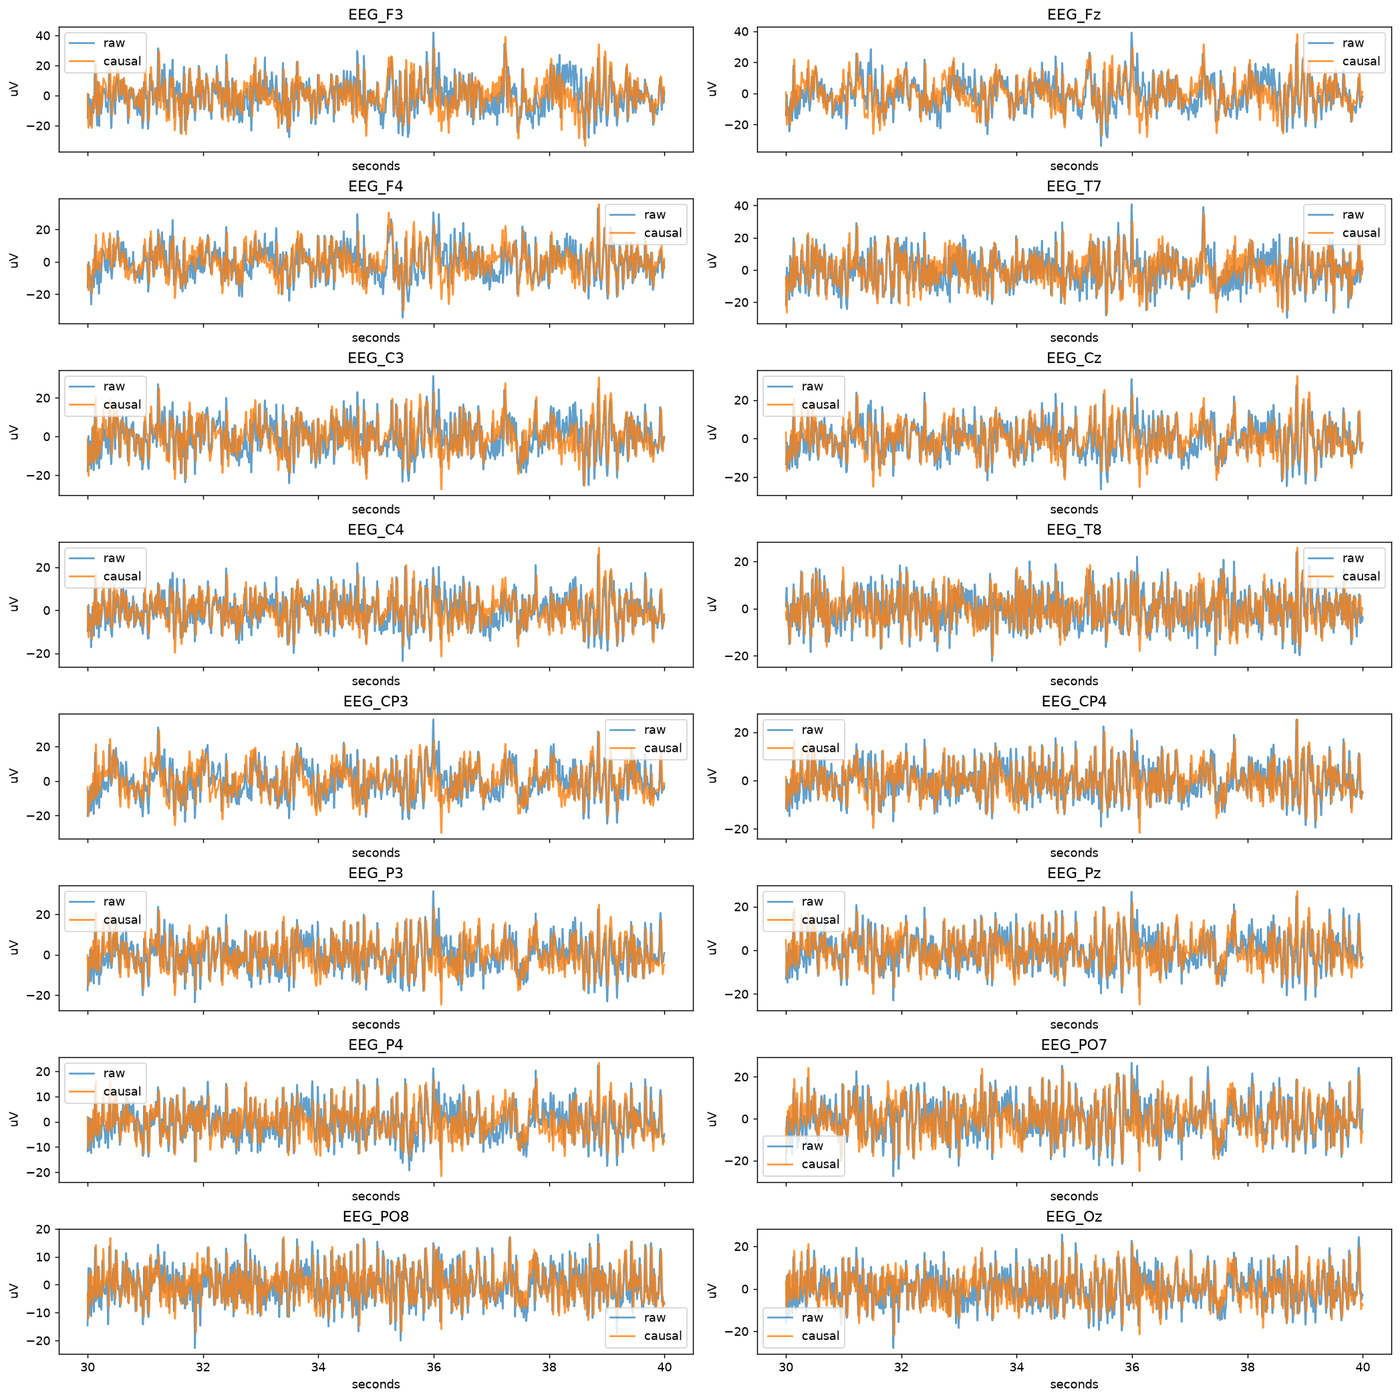

In [11]:
show_saved('ETSU', 'waveform_signal.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

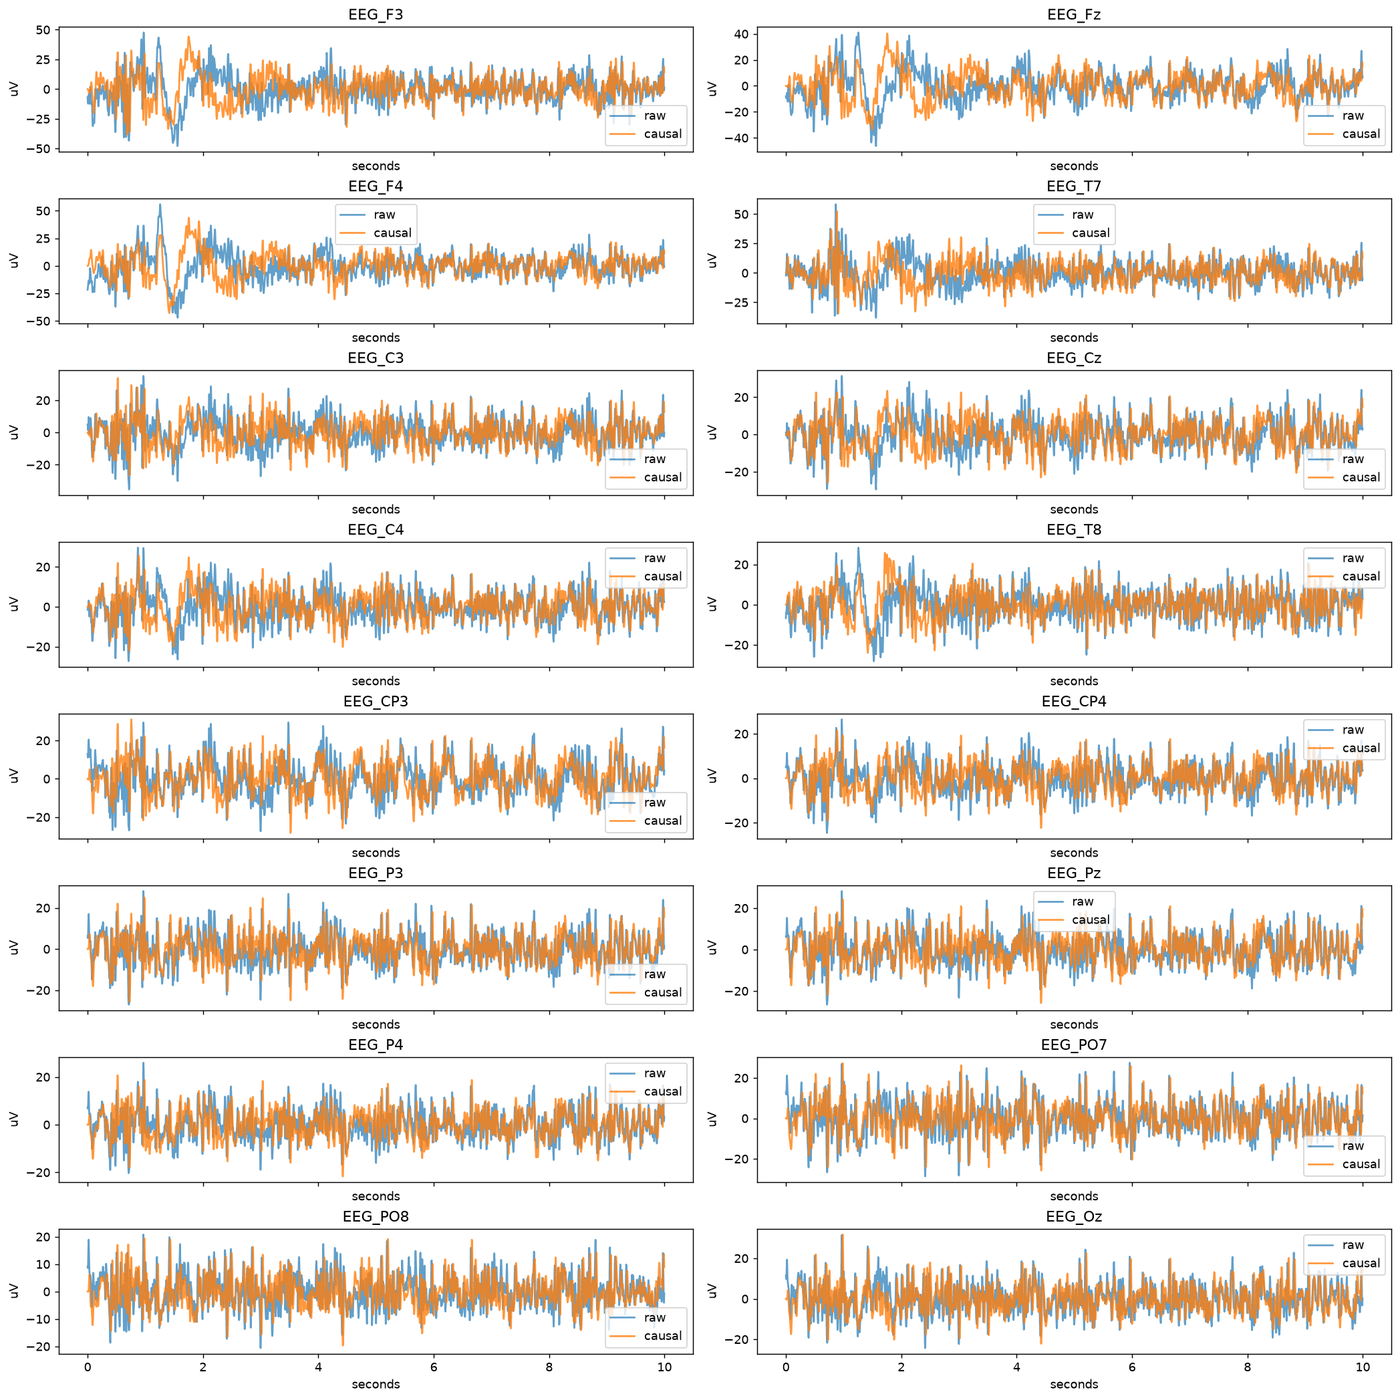

In [12]:
show_saved('ETSU', 'waveform_transient.png')

**启动保护区的含义：**当前候选设置将前 10 秒视为需要保护的启动区，涉及 epoch 无效。这是保守开发选择，不表示已经证明滤波器恰好需要 10 秒稳定。后续可独立验证并调整。瞬变附近的振荡也可能来自真实信号及带通响应；这些图不提供 EOG/ECG/EMG 来源分类。

## 5. 连续通道质量：先看原始数据，避免滤波掩盖平线

2 秒窗、1 秒步长，按当时已完成的历史窗口累计。固定候选阈值检查非有限、常值、全零、低变化及大幅/大波动；不依据整份测试 EDF 的分布重新设阈值。

下表的 fraction 是窗口占比，不是精确异常时间占比，因为窗口重叠。persistent_candidate 表示持续异常候选，需要后续决定通道策略，不能理解成自动删除通道。

In [13]:
for site in FILES:
    display(Markdown(f'**{site}：原始连续通道质量**'))
    display(read_table(site, 'channel_quality.csv'))

**Duke：原始连续通道质量**

,channel,flat_window_fraction,anomaly_window_fraction,persistent_candidate,reasons
0,EEG_F3,0.0,0.0,False,
1,EEG_Fz,0.0,0.0,False,
2,EEG_F4,0.0,0.0,False,
3,EEG_T7,0.0,0.0,False,
4,EEG_C3,0.0,0.0,False,
5,EEG_Cz,0.0,0.0,False,
6,EEG_C4,0.0,0.0,False,
7,EEG_T8,0.0,0.0,False,
8,EEG_CP3,0.0,0.0,False,
9,EEG_CP4,0.0,0.0,False,


**ETSU：原始连续通道质量**

,channel,flat_window_fraction,anomaly_window_fraction,persistent_candidate,reasons
0,EEG_F3,0.0,0.0,False,
1,EEG_Fz,0.0,0.0,False,
2,EEG_F4,0.0,0.0,False,
3,EEG_T7,0.0,0.0,False,
4,EEG_C3,0.0,0.0,False,
5,EEG_Cz,0.0,0.0,False,
6,EEG_C4,0.0,0.0,False,
7,EEG_T8,0.0,0.0,False,
8,EEG_CP3,0.0,0.0,False,
9,EEG_CP4,0.0,0.0,False,


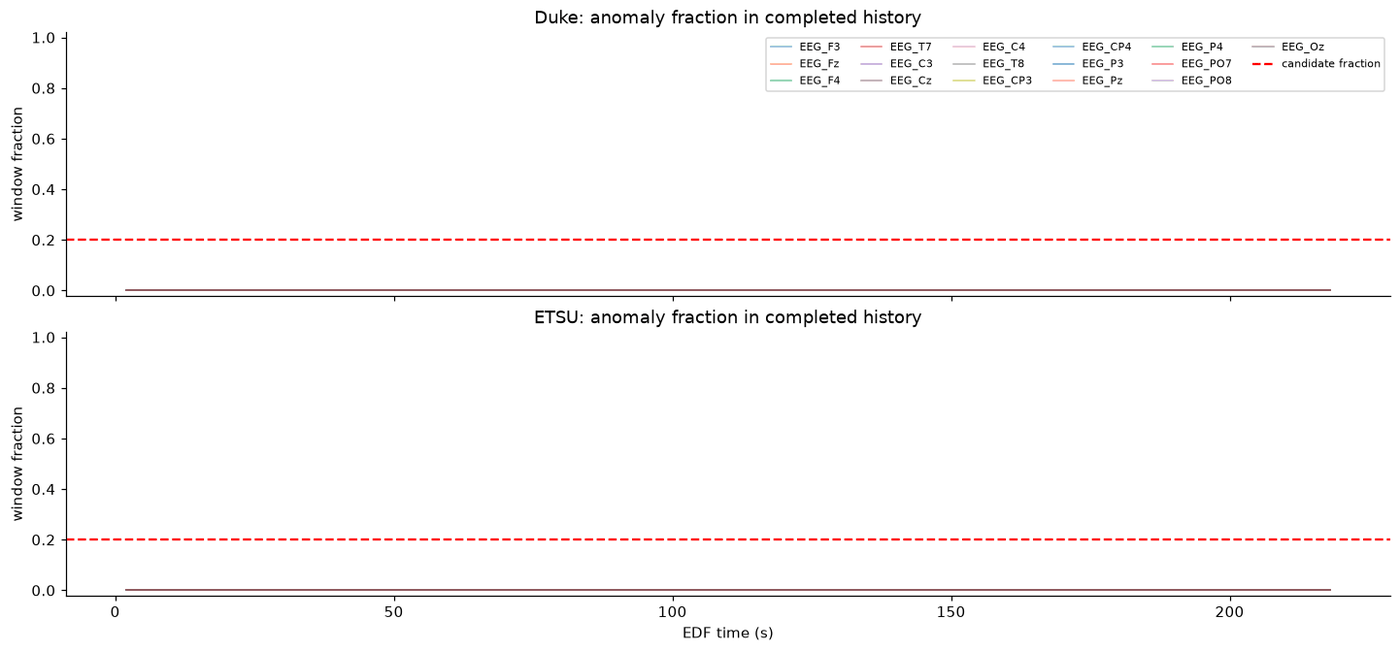

In [14]:
fig, axes=plt.subplots(2,1,figsize=(13,6),sharex=True,sharey=True,layout='constrained')
for ax,site in zip(axes,FILES):
    w=read_table(site,'continuous_windows.csv')
    for channel,g in w.groupby('channel',sort=False):
        ax.plot(g.available_sample / records[site]['sfreq'], g.history_anomaly_fraction,
                label=channel, alpha=.6, linewidth=1)
    ax.axhline(records[site]['config']['continuous_qc']['persistent_fraction'],color='red',ls='--',label='candidate fraction')
    ax.set(title=f'{site}: anomaly fraction in completed history',ylabel='window fraction',ylim=(-.02,1.02))
axes[-1].set_xlabel('EDF time (s)')
axes[0].legend(ncol=6,fontsize=7,loc='upper right')
plt.show()

**本次结果：**两份文件未检出持续异常通道候选，不代表已证明所有片段无伪迹。当前原始平线检查时间尺度为 2 秒，较短平线可能漏检；epoch PTP 提供另一层检查。

如果后续文件出现持续异常：保留 16 通道，相关 epoch 的 `valid_epoch` 留空并标为 `pending_channel_policy`，文件暂不可分类。普通拒绝与“通道策略未确定”必须分开，不能把留空当作通过。

## 6. Epoch 的样本窗口与事件、字符对应关系

每次 flash onset 为零点，提取 `[onset, onset + ceil(0.8×sfreq))`。256 Hz 下为 **205 个样本**，最后一个点是 796.875 ms；800 ms 右端点不包含。在线仍等待完整 800 ms 后判定。相邻 flash 的 epoch 重叠是允许的。

`StimulusType=0/1` 已在原有代码确认对应 non-target/target；`SelectedTarget` 上升沿作为字符结束边界。下面展示所有事件表的前几行，包括无效 epoch，没有只留下通过记录。Baseline=None。

In [15]:
columns=['event_index','subject_id','session_id','site','edf_name','condition',
         'character_trial_id','flash_index','onset_sample','onset_seconds','stimulus_code',
         'label','available_sample','decision_seconds','complete_epoch','valid_epoch','rejection_reason']
for site,t in tables.items():
    display(Markdown(f'**{site}**'))
    display(t[columns].head(8))
    print('事件位置未移动：', bool((t.onset_sample==t.original_event_sample).all()),
          '；完整窗口：', int(t.complete_epoch.sum()), '/', len(t),
          '；未知字符边界：', int((~t.character_boundary_known).sum()))

**Duke**

,event_index,subject_id,session_id,site,edf_name,condition,character_trial_id,flash_index,onset_sample,onset_seconds,stimulus_code,label,available_sample,decision_seconds,complete_epoch,valid_epoch,rejection_reason
0,0,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,1,1152,4.50,1.0,non-target,1356,5.30,True,False,filter_startup
1,1,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,2,1216,4.75,2.0,target,1420,5.55,True,False,filter_startup
2,2,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,3,1280,5.00,3.0,non-target,1484,5.80,True,False,filter_startup
3,3,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,4,1344,5.25,4.0,non-target,1548,6.05,True,False,filter_startup
4,4,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,5,1408,5.50,5.0,non-target,1612,6.30,True,False,filter_startup
5,5,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,6,1472,5.75,6.0,non-target,1676,6.55,True,False,filter_startup
6,6,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,7,1536,6.00,7.0,non-target,1740,6.80,True,False,filter_startup
7,7,F_05,SE001,Duke,F_05_SE001_CBCol_Train02.edf,CBCol,1,8,1600,6.25,8.0,non-target,1804,7.05,True,False,filter_startup


事件位置未移动： True ；完整窗口： 756 / 756 ；未知字符边界： 0


**ETSU**

,event_index,subject_id,session_id,site,edf_name,condition,character_trial_id,flash_index,onset_sample,onset_seconds,stimulus_code,label,available_sample,decision_seconds,complete_epoch,valid_epoch,rejection_reason
0,0,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,1,1152,4.50,1.0,non-target,1356,5.30,True,False,filter_startup
1,1,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,2,1216,4.75,2.0,non-target,1420,5.55,True,False,filter_startup
2,2,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,3,1280,5.00,3.0,non-target,1484,5.80,True,False,filter_startup
3,3,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,4,1344,5.25,4.0,target,1548,6.05,True,False,filter_startup
4,4,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,5,1408,5.50,5.0,non-target,1612,6.30,True,False,filter_startup
5,5,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,6,1472,5.75,6.0,non-target,1676,6.55,True,False,filter_startup
6,6,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,7,1536,6.00,7.0,non-target,1740,6.80,True,False,filter_startup
7,7,F_03,SE001,ETSU,F_03_SE001_CBCol_Train01.edf,CBCol,1,8,1600,6.25,8.0,non-target,1804,7.05,True,False,filter_startup


事件位置未移动： True ；完整窗口： 756 / 756 ；未知字符边界： 0


**如何理解：**onset_sample 是原始文件内样本位置；available_sample 是提取所需最后一个样本，decision_seconds 是最早等待满 800 ms 的时间。重复目标字符不会合并 trial，因为边界不靠 CurrentTarget 的 unique 数量推断。若末尾窗口不足，事件仍保留，complete_epoch=False 并记录 incomplete；本次两份文件没有此类事件。

## 7. PTP 分布与少量候选阈值

PTP = 每个 epoch、每个 QC 通道的最大值减最小值，**在统一因果滤波之后计算**。图中单位 µV，实现内部转换为 V 比较。高 PTP 提示残留大幅异常，低 PTP 提示近乎平直，但两者都不是伪迹来源诊断。

直方图每格是一个通道的逐 epoch 分布。阈值候选为 (0.5,150)、(0.5,250)、(0.2,350) µV；当前选第二组仅为了输出一套可检查的质量表。这些不是已验证的最终标准。标签不参与是否通过的判定。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

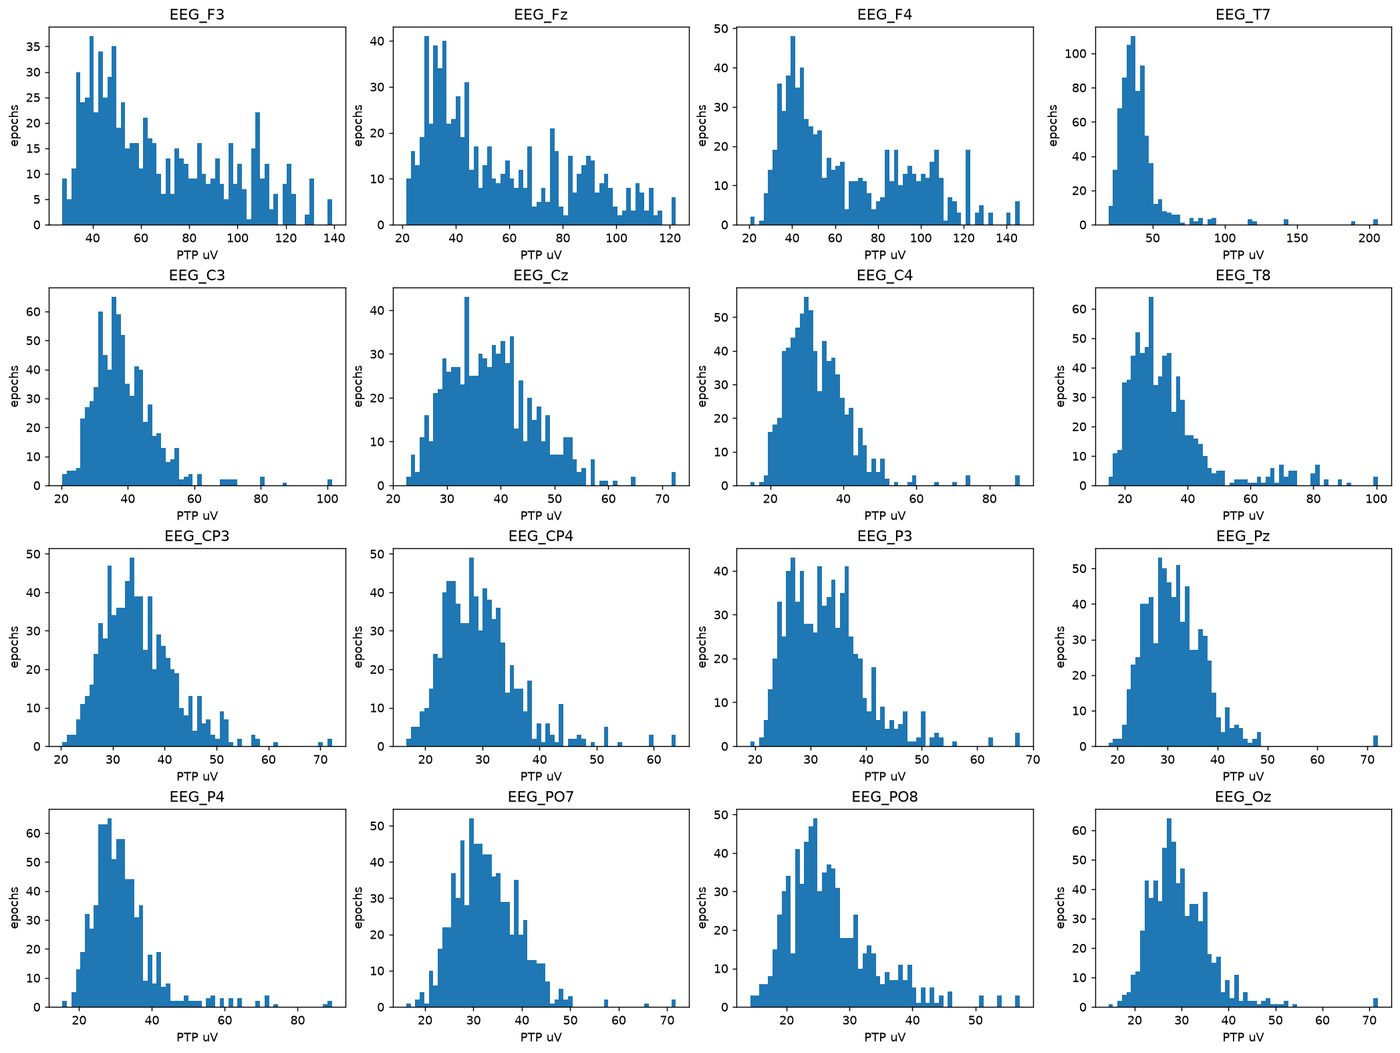

In [16]:
show_saved('Duke', 'ptp_distributions.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

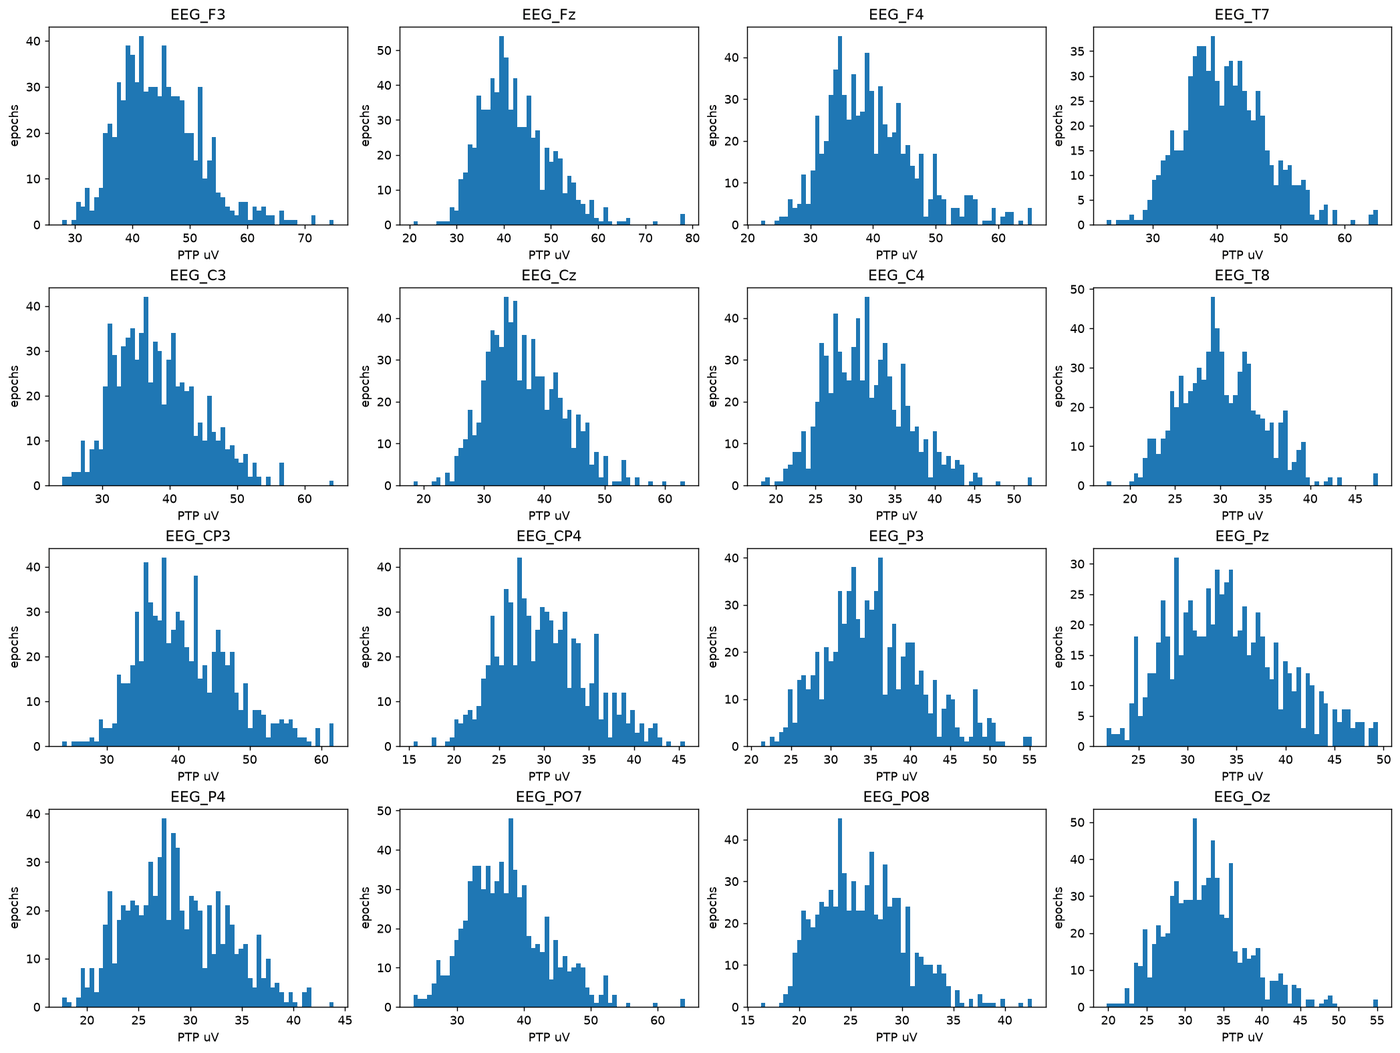

In [17]:
show_saved('ETSU', 'ptp_distributions.png')

,candidate,low_uv,high_uv,n_total,n_valid,n_pending,retention,site
0,0,0.5,150.0,756,729,0,0.964286,Duke
1,1,0.5,250.0,756,734,0,0.970899,Duke
2,2,0.2,350.0,756,734,0,0.970899,Duke
3,0,0.5,150.0,756,734,0,0.970899,ETSU
4,1,0.5,250.0,756,734,0,0.970899,ETSU
5,2,0.2,350.0,756,734,0,0.970899,ETSU


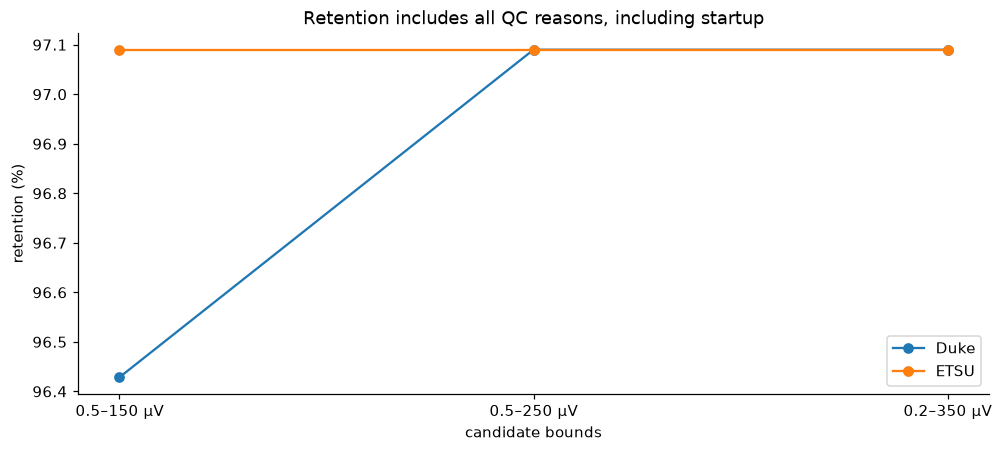

**Duke · 严格候选（0.5–150 µV）的通道触发数**

,count
EEG_T7,5


**ETSU · 严格候选（0.5–150 µV）的通道触发数**

,count


In [18]:
comparison=pd.concat([read_table(site,'threshold_comparison.csv').assign(site=site) for site in FILES],ignore_index=True)
display(comparison)
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
for site,g in comparison.groupby('site',sort=False):
    ax.plot(g.candidate,g.retention*100,marker='o',label=site)
ax.set(xticks=[0,1,2],xticklabels=['0.5–150 µV','0.5–250 µV','0.2–350 µV'],
       ylabel='retention (%)',xlabel='candidate bounds',title='Retention includes all QC reasons, including startup')
ax.legend(); plt.show()
for site in FILES:
    display(Markdown(f'**{site} · 严格候选（0.5–150 µV）的通道触发数**'))
    display(pd.read_csv(OUT / FILES[site] / 'candidate_0_channel_triggers.csv', index_col=0))

**本次结果：**默认候选两站各保留 734/756。严格 150 µV 上限使 Duke 保留数降为 729，由 EEG_T7 触发 5 个；ETSU 仍为 734。候选比较中的保留率包括启动等全部无效原因，不只是 PTP。

这说明结果会受上限影响，**不能据此直接选择保留率最高的一组**。最终选择还需遵守验证划分及 calibration budget，并用已完整检查的人工区间验证；未检查区间不能当作正常。本次没有用人工 annotation 校准阈值，也没有使用测试分布。

## 8. 沿时间查看每个 epoch 的质量与拒绝原因

上图显示每个 epoch 的跨 QC 通道最大 PTP；红叉表示默认规则无效，灰色区域为启动保护区。下图为逐事件状态，便于分清异常集中在何时。这里只画最大 PTP，完整逐通道数值见 `epoch_ptp_uv.csv`。

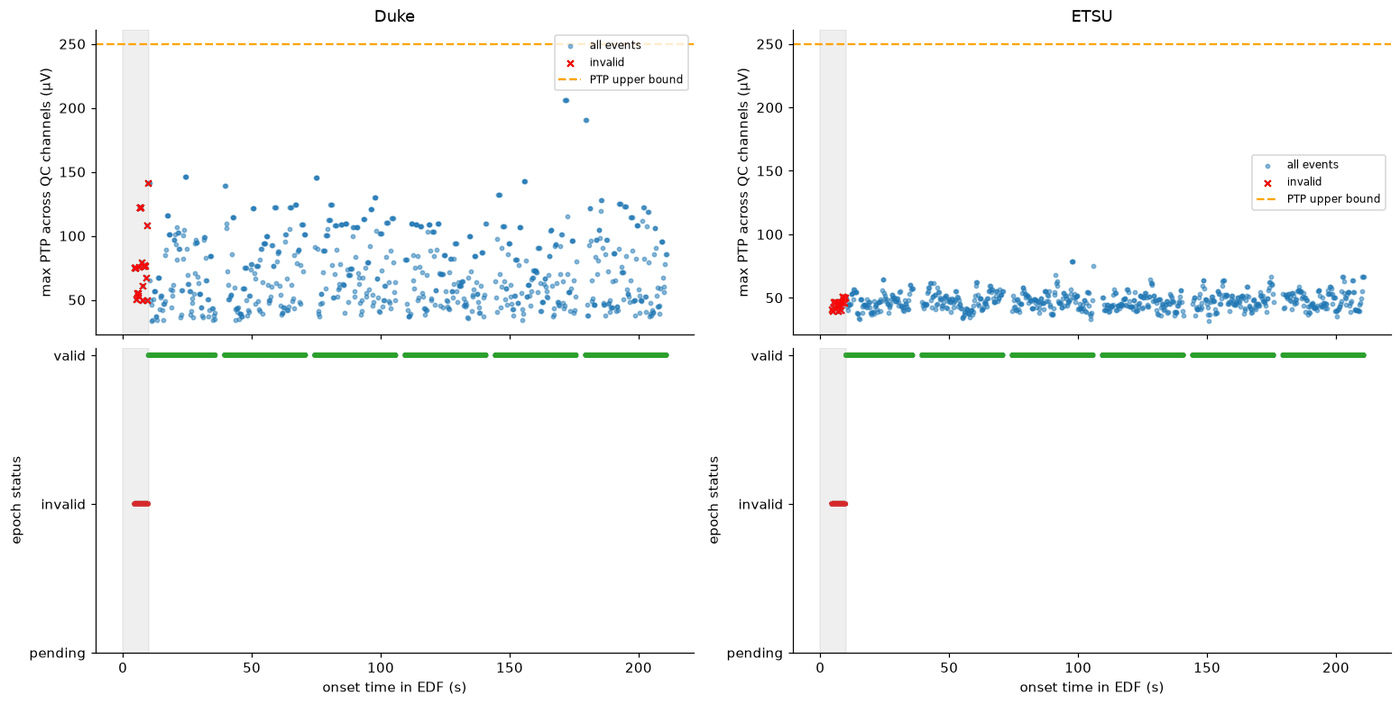

**Duke：默认候选的拒绝原因及触发通道**

,events
filter_startup,22


,events


**ETSU：默认候选的拒绝原因及触发通道**

,events
filter_startup,22


,events


In [19]:
fig,axes=plt.subplots(2,2,figsize=(14,7),sharex='col',layout='constrained')
for col,(site,t) in enumerate(tables.items()):
    valid=t.valid_epoch.fillna(False).to_numpy(dtype=bool)
    pending=t.valid_epoch.isna().to_numpy()
    invalid=(~valid)&(~pending)
    hi=records[site]['config']['epoch_qc']['candidate_bounds_uv'][records[site]['config']['epoch_qc']['selected_candidate']][1]
    axes[0,col].scatter(t.onset_seconds,t.max_ptp_uv,s=8,label='all events',alpha=.5)
    axes[0,col].scatter(t.loc[invalid,'onset_seconds'],t.loc[invalid,'max_ptp_uv'],marker='x',s=20,c='red',label='invalid')
    axes[0,col].axhline(hi,color='orange',ls='--',label='PTP upper bound')
    axes[0,col].set(title=site,ylabel='max PTP across QC channels (µV)')
    axes[0,col].legend(fontsize=8)
    state=np.where(pending,-1,np.where(valid,1,0))
    axes[1,col].scatter(t.onset_seconds,state,c=np.where(pending,'orange',np.where(valid,'tab:green','tab:red')),s=9)
    axes[1,col].set(yticks=[-1,0,1],yticklabels=['pending','invalid','valid'],xlabel='onset time in EDF (s)',ylabel='epoch status')
    for ax in axes[:,col]: ax.axvspan(0,records[site]['config']['filter']['startup_seconds'],alpha=.12,color='gray')
plt.show()
for site,t in tables.items():
    display(Markdown(f'**{site}：默认候选的拒绝原因及触发通道**'))
    reasons=t.rejection_reason.fillna('').str.get_dummies(sep=';').sum().rename('events')
    channels=t.trigger_channels.fillna('').str.get_dummies(sep=';').sum().rename('events')
    display(reasons.to_frame()); display(channels.to_frame())

**本次结果：**两站默认候选均只有 `filter_startup=22`，没有 PTP 触发通道。空的通道触发表是“没有通道触发拒绝”，不是结果丢失。启动保护由时间触发，所以不归属于某个通道。

同一 epoch 可以有多个原因、多个触发通道，计数相加可能大于拒绝总数。不合格 flash 后续不提供分类分数，也不填 0；同一字符的其他合格 flash 继续保留。

## 9. EDF / subject / session 与类别保留率

总保留率使用全部 flash 为分母；另列 pending，避免把未确定有效性当作普通通过或拒绝。target/non-target 分开统计只用于观察 QC 对类别保留的影响，标签本身没有参与 QC。

,site,edf_name,total,valid,pending,retention_pct
0,Duke,F_05_SE001_CBCol_Train02.edf,756,734,0,97.09
1,ETSU,F_03_SE001_CBCol_Train01.edf,756,734,0,97.09


,subject_id,total,valid,pending,retention_pct
0,F_05,756,734,0,97.09
1,F_03,756,734,0,97.09


,subject_id,session_id,total,valid,pending,retention_pct
0,F_05,SE001,756,734,0,97.09
1,F_03,SE001,756,734,0,97.09


,site,label,total,valid,pending,retention_pct
0,Duke,non-target,672,653,0,97.173
1,Duke,target,84,81,0,96.429
2,ETSU,non-target,672,653,0,97.173
3,ETSU,target,84,81,0,96.429


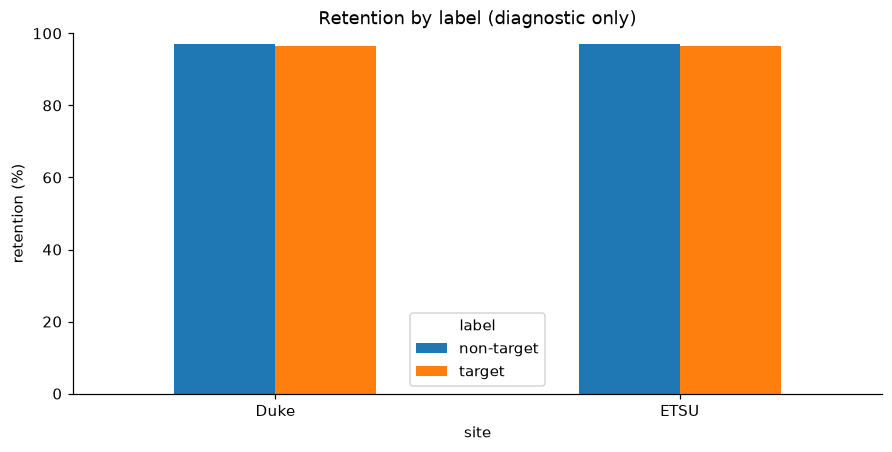

In [20]:
all_events=pd.concat(tables.values(),ignore_index=True)
def quality_summary(frame,keys):
    rows=[]
    for key,g in frame.groupby(keys,dropna=False,sort=False):
        key=key if isinstance(key,tuple) else (key,)
        n_valid=int(g.valid_epoch.fillna(False).sum())
        rows.append(dict(zip(keys,key)) | {'total':len(g),'valid':n_valid,
                    'pending':int(g.valid_epoch.isna().sum()),'retention_pct':100*n_valid/len(g)})
    return pd.DataFrame(rows)
for keys in [['site','edf_name'],['subject_id'],['subject_id','session_id'],['site','label']]:
    display(quality_summary(all_events,keys).round(3))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
label_summary=quality_summary(all_events,['site','label'])
label_summary.pivot(index='site',columns='label',values='retention_pct').plot.bar(ax=ax,ylim=(0,100),rot=0)
ax.set(ylabel='retention (%)',title='Retention by label (diagnostic only)'); plt.show()

**本次结果：**每站 target 为 81/84（96.43%），non-target 为 653/672（97.17%）。小幅差异来自前 10 秒包含的标签数量差异，不表示算法使用了标签拒绝。每站当前只有一个 subject/session/EDF，因此三个汇总层级数值相同，不能看成三组独立验证。

## 10. 每个 character trial 还有多少可用 flash？

下面同时画总数和有效数。一次异常只影响对应 flash，不自动删除整个字符。当前 `evidence_insufficient` 仅标记有效 flash 为零；其他最小证据量、字符评分及停止规则尚未决定，因此非零不等于“已经足够准确解码”。

**Duke**

,character_trial_id,total_flashes,valid_flashes,pending_flashes,evidence_insufficient,scoring_policy
0,1,126,104,0,False,pending; only zero valid flashes is flagged as...
1,2,126,126,0,False,pending; only zero valid flashes is flagged as...
2,3,126,126,0,False,pending; only zero valid flashes is flagged as...
3,4,126,126,0,False,pending; only zero valid flashes is flagged as...
4,5,126,126,0,False,pending; only zero valid flashes is flagged as...
5,6,126,126,0,False,pending; only zero valid flashes is flagged as...


**ETSU**

,character_trial_id,total_flashes,valid_flashes,pending_flashes,evidence_insufficient,scoring_policy
0,1,126,104,0,False,pending; only zero valid flashes is flagged as...
1,2,126,126,0,False,pending; only zero valid flashes is flagged as...
2,3,126,126,0,False,pending; only zero valid flashes is flagged as...
3,4,126,126,0,False,pending; only zero valid flashes is flagged as...
4,5,126,126,0,False,pending; only zero valid flashes is flagged as...
5,6,126,126,0,False,pending; only zero valid flashes is flagged as...


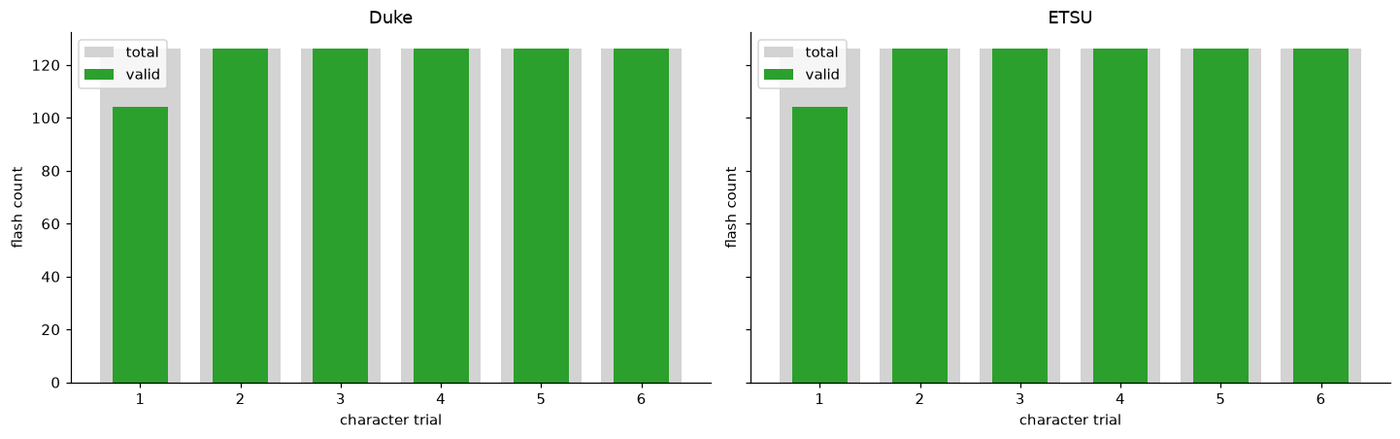

In [21]:
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True,layout='constrained')
for ax,site in zip(axes,FILES):
    c=read_table(site,'character_trials.csv')
    display(Markdown(f'**{site}**')); display(c)
    ax.bar(c.character_trial_id,c.total_flashes,label='total',color='lightgray')
    ax.bar(c.character_trial_id,c.valid_flashes,label='valid',width=.55,color='tab:green')
    ax.set(title=site,xlabel='character trial',ylabel='flash count',xticks=c.character_trial_id)
    ax.legend()
plt.show()

**本次结果：**每站 6 个字符、每字符 126 次 flash。首字符保留 104 次，其余各 126 次；首字符没有因启动期损失而被整段删除。

## 11. 拒绝前后的 target / non-target 平均 ERP

红色为 target，蓝色为 non-target；虚线为拒绝前，实线为拒绝后。所有曲线来自**同一份因果滤波数据**，不是原始与滤波后的比较。每格使用共享坐标，图例的 n 是参与平均的 epoch 数。

拒绝前只平均完整窗口（包含启动期），拒绝后只平均有效窗口；Baseline=None，事件没有延迟校正。信号受到因果相位响应及相邻 flash 重叠影响，不能把图中每个峰直接归因于单次刺激或伪迹来源。

**Duke（站点推断） · F_05_SE001_CBCol_Train02**

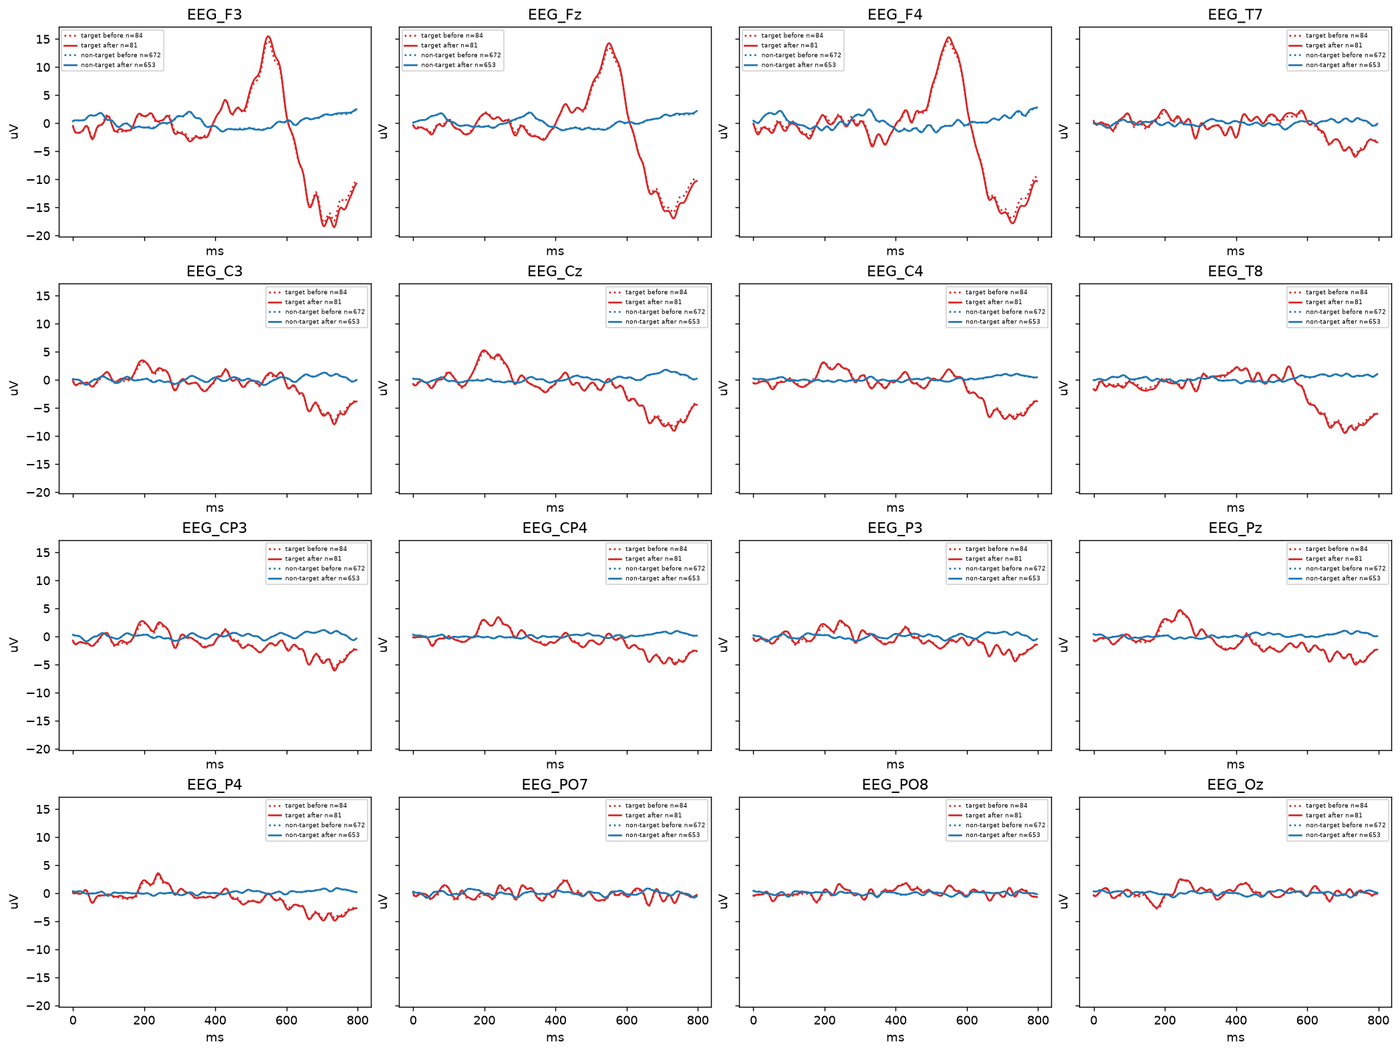

In [22]:
show_saved('Duke', 'erp_before_after.png')

**ETSU（站点推断） · F_03_SE001_CBCol_Train01**

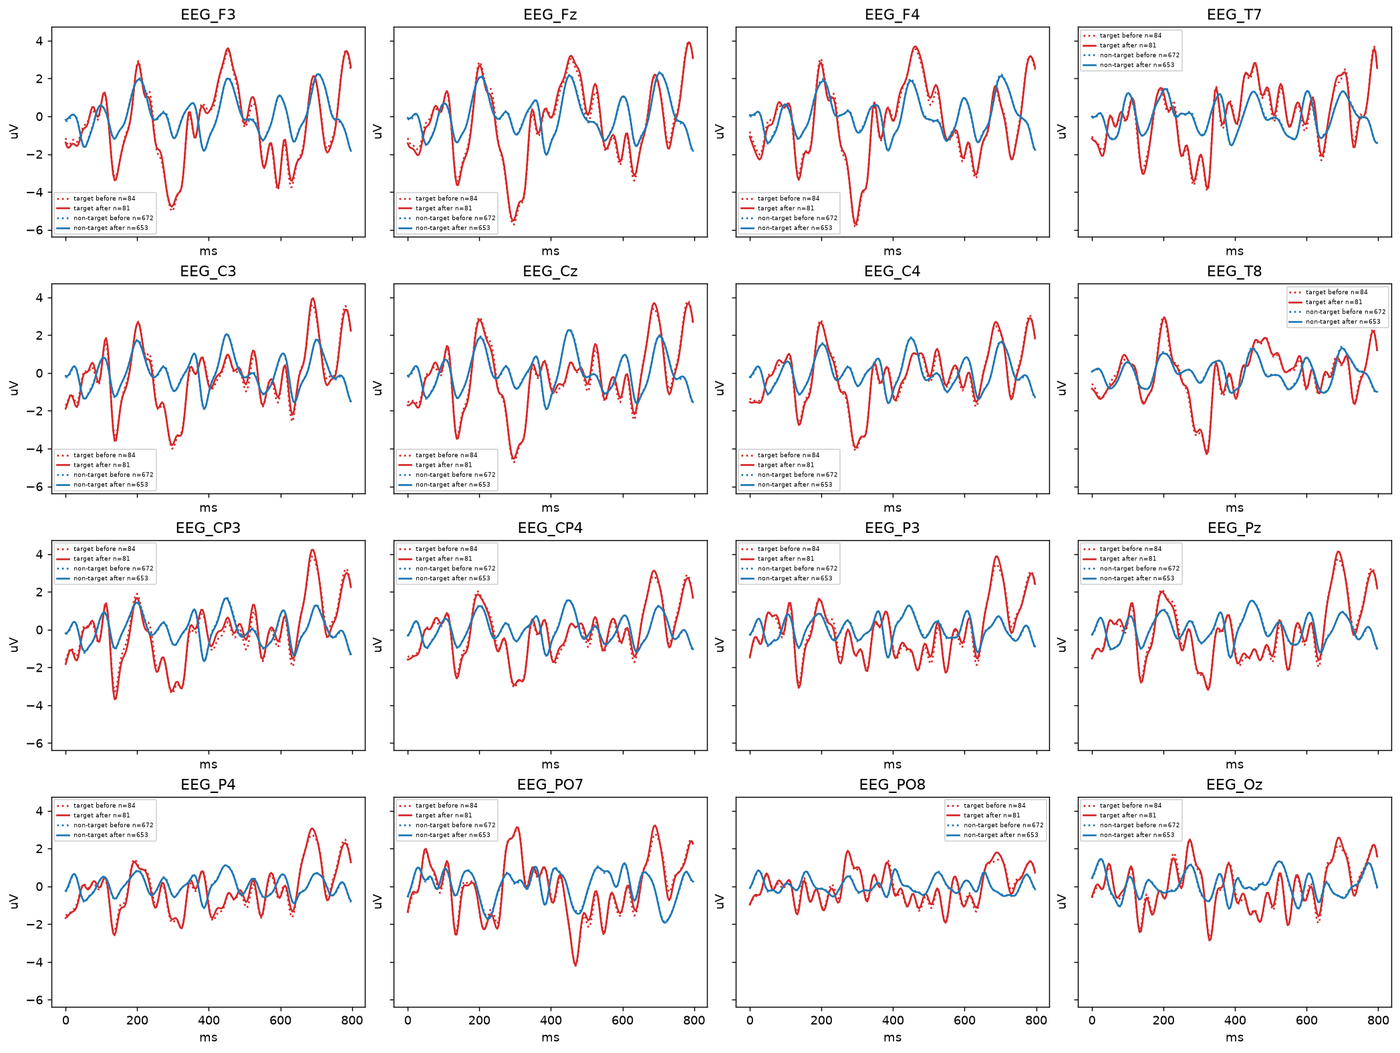

In [23]:
show_saved('ETSU', 'erp_before_after.png')

**如何理解：**两站拒绝后均为 target n=81、non-target n=653，拒绝前分别 n=84/672。前后接近说明本次删去的少量启动 epoch 对文件平均的影响有限，**不证明所有伪迹已清除，也不证明阈值最优或模型有效**。不同通道形态不同，不能因为某个通道波形不典型就直接删除它。

本 notebook 的人工浏览只服务开发和验证；正式测试应使用冻结自动规则，不根据这些图逐段手动删数据。

## 12. 产物一致性检查与后续边界

最后检查图表背后的事件数量、样本数和有效标记是否一致。原始 EDF 的读前/读后 SHA256 校验已由预处理脚本执行并写入 processing_record.json；本 notebook 只读取产物，不重新声称对源 EDF 执行了校验。

当前仍待研究确定：最终 epoch 阈值、启动保护长度、持续坏通道处理策略、calibration budget 下的阈值估计、字符证据量与评分/停止规则。未加入 ICA、EOG/ECG/EMG 来源分类、插值、训练或 baseline correction。

In [24]:
checks=[]
for site,t in tables.items():
    with np.load(OUT / FILES[site] / 'epochs_all.npz',allow_pickle=False) as e:
        assert len(t)==len(e['event_index'])==e['eeg_v'].shape[0]
        assert e['eeg_v'].shape[1]==16
        assert e['eeg_v'].shape[2]==records[site]['epoch_samples']
        np.testing.assert_array_equal(e['valid_epoch'],t.valid_epoch.fillna(False).to_numpy(dtype=bool))
        np.testing.assert_array_equal(e['event_index'],t.event_index.to_numpy())
    assert t.onset_sample.is_monotonic_increasing
    assert (t.onset_sample==t.original_event_sample).all()
    checks.append({'site':site,'artifact_checks':'PASS','source_sha256_recorded':records[site]['source_sha256']})
display(pd.DataFrame(checks))

,site,artifact_checks,source_sha256_recorded
0,Duke,PASS,dacb2d28edcb5449ddac9b1d6d23667120c389bc5ac0fc...
1,ETSU,PASS,fc05d9087c3c63da96da095029341a19043f85a71cf46b...
